# Cosmetic ingredient alert — Random Forest final project

**Ironhack Data Science final · reproducible notebook · fresh execution required**

This notebook traces the supplied Open Beauty Facts-style snapshots from collection evidence through an **UNMASKED supplied-label reproduction** experiment. It is deliberately not a toxicology study, an ingredient safety classifier, or a reconstruction of an unknown registry. The target is the supplied binary `has_risk` label.

The model is an ingredient-list Random Forest. It is an ensemble-focused project: Logistic Regression, a majority baseline, and (when installed and feasible) HistGradientBoosting are genuine benchmarks. Their measured CV results are reported, but this notebook does **not** make a blanket claim that Random Forest is the global winner across all possible model families or datasets.

**Safety and regulatory disclaimer.** A positive model score is only a predicted supplied-label alert; it is not evidence that an ingredient is toxic, prohibited, unsafe at a given concentration, or unsuitable for a person. A negative score does not establish safety. Regulation, exposure, concentration, formulation interactions, allergies, and jurisdiction are outside this dataset.

## 1. Goal, provenance, and evaluation plan

**Question.** Can normalized, parsed ingredient lists reproduce the supplied labels while preventing repeated formulas from leaking between training and evaluation?

The supplied collection metadata says that the historical process referred to **16 reference substances**, but the names, aliases, source version, inclusion rule, and historical labeling code are not included. We therefore preserve supplied labels and never manufacture a registry, infer a deterministic rule, or hide any observations because of an unknown registry. `masking_applied` must remain `false` in the final report.

The project uses a formula-grouped held-out split. Inside the training partition, grouped CV benchmarks the candidates, tunes the Random Forest on **average precision**, and obtains out-of-fold (OOF) scores. The operational threshold maximizes **F2** among OOF thresholds that achieve recall ≥ 0.95. The independent grouped holdout is used only after those choices are fixed.

Run time: a fresh execution fits grouped CV models plus four Random Forest hyperparameter combinations and can take several minutes. The notebook intentionally calls `run_experiments(..., folds=3)` by default; it does not silently claim a cached training run. `COSMETIC_RETRAIN` is displayed for traceability only and does not suppress training.

In [1]:
from pathlib import Path
import ast
import hashlib
import inspect
import io
import json
import os
import sqlite3
import sys
import time

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

# Locate the repository whether Jupyter starts in the project root or notebooks/.
search_roots = [Path.cwd(), *Path.cwd().parents, Path('/home/ubuntu/ironhack-random-forest-final')]
ROOT = next((path for path in search_roots if (path / 'src' / 'cleaning.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the project root or its notebooks/ directory.')
sys.path.insert(0, str(ROOT))
for relative in ('reports/figures', 'reports/tables', 'models'):
    (ROOT / relative).mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 16)
pd.set_option('display.max_colwidth', 72)
pd.set_option('display.width', 140)
print('Project root:', ROOT)
print('Fresh training is enabled. COSMETIC_RETRAIN =', os.getenv('COSMETIC_RETRAIN', '<unset>'))

Project root: /home/ubuntu/ironhack-random-forest-final
Fresh training is enabled. COSMETIC_RETRAIN = <unset>


## 2. Collection evidence: local bulk snapshots and an offline API response

This section reads only local artifacts. The bulk CSV snapshot is the provenance of the labeled data. A saved public-API response is a small, separately preserved acquisition example; it is **not** represented as the source of historical labels. No network request is issued by this notebook.

In [2]:
metadata_path = ROOT / 'data' / 'collection_metadata.json'
manifest_path = ROOT / 'data' / 'file_manifest.json'
metadata = json.loads(metadata_path.read_text(encoding='utf-8')) if metadata_path.exists() else {}
manifest = json.loads(manifest_path.read_text(encoding='utf-8')) if manifest_path.exists() else {}
print('Collection metadata')
display(pd.Series(metadata, name='value'))
if manifest:
    print('Distributed-file manifest')
    display(pd.json_normalize(manifest).T.rename(columns={0: 'value'}))

api_dir = ROOT / 'data' / 'api'
api_files = sorted(api_dir.glob('*.json')) if api_dir.exists() else []
print('Saved API snapshot files:', [path.name for path in api_files])
for path in api_files:
    payload = json.loads(path.read_text(encoding='utf-8'))
    print(f'Offline API artifact: {path.name}')
    if isinstance(payload, dict):
        display(pd.json_normalize(payload, sep='.').T.head(40).rename(columns={0: 'value'}))
    else:
        display(payload)

collection_source = ROOT / 'src' / 'collection.py'
if collection_source.exists():
    print('Collection implementation (shown for audit; not invoked):')
    display(Markdown('```python\n' + collection_source.read_text(encoding='utf-8') + '\n```'))
else:
    print('No collection module is present. Do not claim a live API acquisition.')

Collection metadata


source                  https://fr.openbeautyfacts.org/data/fr.openbeautyfacts.org.products.csv
download_date                                                        2026-10-10T14:40:32.599113
raw_rows                                                                                  64237
filtered_rows                                                                             17354
reference_substances                                                                         16
columns_used              [code, product_name, brands, categories, ingredients_text, countries]
Name: value, dtype: object

Distributed-file manifest


,value,1,2,3,4
path,data/raw/obf_france.csv,data/interim/obf_with_ingredients.csv,data/processed/products_labeled.csv,data/processed/products_clean.csv,data/api/product_snapshot.json
bytes,170994238,63474167,65860522,35250427,171353
sha256,1277cd57b9b12cb3aa9bc55780b45a370c4215e823ae415820829ff0fd111c09,00c3c7c5a583b86fd229293a45f0f4b7a1a230e87ed2351dda20eb334c2ccef1,cddc8e6cc3d30ca8bdb11f0b14a1915091332e950b332285e1cae989f0aa03c2,e55ec3b5f5368d5e2dafcd56d75b4d3d1ff25ab6d0c4bae4ef2951b1c447c998,b8e4081da11cc7e07aa1fc392a478cb7725fd0d711c79b007b4adf07d1fc2481


Saved API snapshot files: ['product_snapshot.json']
Offline API artifact: product_snapshot.json


,value
snapshot_schema_version,1
collection_type,api_product_sample
results,"[{'barcode': '1785', 'request_url': 'https://world.openbeautyfacts.o..."
metadata.collected_at_utc,2026-10-31T02:38:53Z
metadata.source_base_url,https://world.openbeautyfacts.org
metadata.source_product_endpoint_template,https://world.openbeautyfacts.org/api/v2/product/{barcode}.json
metadata.request_policy.serial,True
metadata.request_policy.live_product_cap,3
metadata.request_policy.timeout_seconds.connect,5.0
metadata.request_policy.timeout_seconds.read,30.0


Collection implementation (shown for audit; not invoked):


```python
"""Collect a small, auditable Open Beauty Facts API sample or an explicit bulk CSV.

Run from the repository root, for example:
    python -m src.collection --from-labeled-csv /home/ubuntu/upload/products_labeled.csv

The default operation never crawls the API: it requires explicit barcode input and
caps live product requests at a small serial sample.  The bulk download is opt-in.
"""

from __future__ import annotations

import argparse
import csv
import hashlib
import json
import random
import re
import sys
import time
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Callable, Iterable, Mapping, Sequence
from urllib.parse import quote

import requests

DEFAULT_BASE_URL = "https://world.openbeautyfacts.org"
PRODUCT_PATH_TEMPLATE = "/api/v2/product/{barcode}.json"
DEFAULT_BULK_CSV_URL = (
    "https://static.openbeautyfacts.org/data/"
    "en.openbeautyfacts.org.products.csv.gz"
)
DEFAULT_OUTPUT = Path("data/api/product_snapshot.json")
DEFAULT_MAX_PRODUCTS = 3
DEFAULT_TIMEOUT: tuple[float, float] = (5.0, 30.0)
DEFAULT_USER_AGENT = (
    "IronhackCosmeticRiskDetector/1.0 "
    "(educational collector; set a reachable contact before production use)"
)

# Provenance supplied for the project CSV.  It describes that existing source, not
# the scope of a product's country fields or the timestamp of a fresh API response.
LABELED_CSV_PROVENANCE = {
    "original_download_date": "2026-10-10",
    "original_source": "fr.openbeautyfacts.org export",
    "scope_note": (
        "An export sourced from fr.openbeautyfacts.org is not evidence that its "
        "products are France-only."
    ),
}

_BARCODE_RE = re.compile(r"^[0-9A-Za-z._-]{1,64}$")
_RETRIABLE_STATUS_CODES = {429, 500, 502, 503, 504}


class CollectionError(RuntimeError):
    """Raised for local input or download errors that should stop the CLI."""


def utc_now() -> str:
    """Return an RFC 3339 UTC timestamp with second precision."""
    return datetime.now(timezone.utc).replace(microsecond=0).isoformat().replace("+00:00", "Z")


def normalise_base_url(base_url: str) -> str:
    """Return an HTTPS base URL without a trailing slash."""
    base_url = base_url.strip().rstrip("/")
    if not base_url.startswith("https://"):
        raise CollectionError("--base-url must use https://")
    return base_url


def product_url(base_url: str, barcode: str) -> str:
    """Build a product endpoint URL while preserving the barcode text unchanged."""
    if not isinstance(barcode, str) or not _BARCODE_RE.fullmatch(barcode):
        raise CollectionError(
            "Barcode must be a non-empty string of up to 64 letters, digits, dot, underscore, or hyphen."
        )
    return normalise_base_url(base_url) + PRODUCT_PATH_TEMPLATE.format(
        barcode=quote(barcode, safe="")
    )


def read_labeled_barcodes(csv_path: str | Path, limit: int = DEFAULT_MAX_PRODUCTS) -> list[str]:
    """Read up to *limit* valid codes from a comma-delimited labeled CSV.

    CSV values remain strings: no integer conversion, zero-padding, or other
    barcode normalization is performed.
    """
    if limit < 1:
        raise CollectionError("limit must be at least 1")

    path = Path(csv_path)
    try:
        with path.open("r", encoding="utf-8-sig", newline="") as handle:
            reader = csv.DictReader(handle)
            if not reader.fieldnames or "code" not in reader.fieldnames:
                raise CollectionError(f"{path} must contain a comma-delimited 'code' column")
            barcodes: list[str] = []
            for row in reader:
                # Keep the CSV text verbatim. Whitespace-only values are ignored.
                barcode = row.get("code")
                if barcode is None or not barcode.strip():
                    continue
                if not _BARCODE_RE.fullmatch(barcode):
                    continue
                barcodes.append(barcode)
                if len(barcodes) >= limit:
                    break
    except OSError as exc:
        raise CollectionError(f"Could not read labeled CSV {path}: {exc}") from exc

    if not barcodes:
        raise CollectionError(f"No valid barcode strings found in {path}")
    return barcodes


def read_labeled_product_barcodes(csv_path: str | Path, limit: int = DEFAULT_MAX_PRODUCTS) -> list[str]:
    """Prefer named, ingredient-bearing records when sampling the labeled CSV.

    Very short legacy identifiers are retained by :func:`read_labeled_barcodes`,
    but this API-sample helper prefers the stronger local evidence available in
    the project CSV: a code of at least four characters plus product name and
    ingredient text. It never pads, casts, or otherwise changes the code string.
    If too few preferred records exist, valid codes are used as a fallback.
    """
    if limit < 1:
        raise CollectionError("limit must be at least 1")

    path = Path(csv_path)
    try:
        with path.open("r", encoding="utf-8-sig", newline="") as handle:
            reader = csv.DictReader(handle)
            if not reader.fieldnames or "code" not in reader.fieldnames:
                raise CollectionError(f"{path} must contain a comma-delimited 'code' column")
            preferred: list[str] = []
            fallback: list[str] = []
            for row in reader:
                barcode = row.get("code")
                if barcode is None or not barcode.strip() or not _BARCODE_RE.fullmatch(barcode):
                    continue
                if barcode not in fallback:
                    fallback.append(barcode)
                if (
                    len(barcode) >= 4
                    and bool((row.get("product_name") or "").strip())
                    and bool((row.get("ingredients_text") or "").strip())
                    and barcode not in preferred
                ):
                    preferred.append(barcode)
                    if len(preferred) >= limit:
                        break
    except OSError as exc:
        raise CollectionError(f"Could not read labeled CSV {path}: {exc}") from exc

    selected = (preferred + [barcode for barcode in fallback if barcode not in preferred])[:limit]
    if not selected:
        raise CollectionError(f"No valid barcode strings found in {path}")
    return selected


def _retry_delay(response: Any | None, attempt_index: int, random_fn: Callable[[], float]) -> float:
    """Return a capped exponential delay, honoring integer Retry-After when present."""
    retry_after: str | None = None
    if response is not None:
        headers = getattr(response, "headers", {}) or {}
        retry_after = headers.get("Retry-After")
    if retry_after:
        try:
            return min(float(retry_after), 60.0)
        except (TypeError, ValueError):
            pass
    # 0.5, 1, 2 seconds plus small jitter; bounded so a CLI cannot stall indefinitely.
    return min((0.5 * (2**attempt_index)) + (0.25 * random_fn()), 30.0)


def _get_with_retry(
    session: requests.Session,
    url: str,
    *,
    user_agent: str,
    timeout: tuple[float, float],
    max_retries: int,
    stream: bool = False,
    sleep: Callable[[float], None] = time.sleep,
    random_fn: Callable[[], float] = random.random,
) -> tuple[Any | None, int, str | None]:
    """Perform one GET with bounded retry on network errors, 429, and selected 5xx."""
    last_error: str | None = None
    for attempt in range(max_retries + 1):
        try:
            response = session.get(
                url,
                headers={"User-Agent": user_agent, "Accept": "application/json"},
                timeout=timeout,
                stream=stream,
            )
        except requests.RequestException as exc:
            response = None
            last_error = f"{type(exc).__name__}: {exc}"
        else:
            if response.status_code not in _RETRIABLE_STATUS_CODES:
                return response, attempt + 1, None
            last_error = f"HTTP {response.status_code}"

        if attempt < max_retries:
            sleep(_retry_delay(response, attempt, random_fn))
            if response is not None and hasattr(response, "close"):
                response.close()

    return response, max_retries + 1, last_error


def fetch_product(
    barcode: str,
    *,
    base_url: str = DEFAULT_BASE_URL,
    session: requests.Session | None = None,
    user_agent: str = DEFAULT_USER_AGENT,
    timeout: tuple[float, float] = DEFAULT_TIMEOUT,
    max_retries: int = 2,
    sleep: Callable[[float], None] = time.sleep,
    random_fn: Callable[[], float] = random.random,
) -> dict[str, Any]:
    """Fetch one product and return its response or an honest diagnostic record."""
    if max_retries < 0:
        raise CollectionError("max_retries cannot be negative")

    endpoint = product_url(base_url, barcode)
    client = session if session is not None else requests.Session()
    response, attempts, request_error = _get_with_retry(
        client,
        endpoint,
        user_agent=user_agent,
        timeout=timeout,
        max_retries=max_retries,
        sleep=sleep,
        random_fn=random_fn,
    )

    record: dict[str, Any] = {
        "barcode": barcode,
        "request_url": endpoint,
        "retrieved_at_utc": utc_now(),
        "attempts": attempts,
        "status_code": getattr(response, "status_code", None),
        "outcome": "network_error" if response is None else "http_error",
        "response": None,
        "error": request_error,
    }
    if response is None:
        return record

    try:
        payload = response.json()
    except (ValueError, json.JSONDecodeError) as exc:
        record["outcome"] = "invalid_json"
        record["error"] = f"JSON decode error: {exc}"
        return record
    finally:
        if hasattr(response, "close"):
            response.close()

    record["response"] = payload
    if 200 <= response.status_code < 300:
        api_status = payload.get("status") if isinstance(payload, Mapping) else None
        if api_status == 1:
            record["outcome"] = "ok"
            record["error"] = None
        else:
            record["outcome"] = "api_not_found"
            record["error"] = f"Open Beauty Facts API status {api_status!r}"
    elif record["error"] is None:
        record["error"] = f"HTTP {response.status_code}"
    return record


def collect_product_snapshot(
    barcodes: Sequence[str],
    *,
    base_url: str = DEFAULT_BASE_URL,
    session: requests.Session | None = None,
    user_agent: str = DEFAULT_USER_AGENT,
    timeout: tuple[float, float] = DEFAULT_TIMEOUT,
    max_retries: int = 2,
    input_metadata: Mapping[str, Any] | None = None,
    sleep: Callable[[float], None] = time.sleep,
    random_fn: Callable[[], float] = random.random,
) -> dict[str, Any]:
    """Collect a serial, small product sample suitable for an auditable snapshot."""
    if not barcodes:
        raise CollectionError("At least one barcode is required")
    if len(barcodes) > DEFAULT_MAX_PRODUCTS:
        raise CollectionError(
            f"Live API samples are capped at {DEFAULT_MAX_PRODUCTS} products; use the explicit bulk export for larger work."
        )

    canonical_base = normalise_base_url(base_url)
    client = session if session is not None else requests.Session()
    # Intentionally a normal for-loop: no concurrency and no API crawling behavior.
    records = [
        fetch_product(
            barcode,
            base_url=canonical_base,
            session=client,
            user_agent=user_agent,
            timeout=timeout,
            max_retries=max_retries,
            sleep=sleep,
            random_fn=random_fn,
        )
        for barcode in barcodes
    ]
    return {
        "snapshot_schema_version": 1,
        "collection_type": "api_product_sample",
        "metadata": {
            "collected_at_utc": utc_now(),
            "source_base_url": canonical_base,
            "source_product_endpoint_template": canonical_base + PRODUCT_PATH_TEMPLATE,
            "request_policy": {
                "serial": True,
                "live_product_cap": DEFAULT_MAX_PRODUCTS,
                "timeout_seconds": {"connect": timeout[0], "read": timeout[1]},
                "max_retries": max_retries,
                "retry_statuses": sorted(_RETRIABLE_STATUS_CODES),
                "user_agent": user_agent,
            },
            "input": dict(input_metadata or {}),
        },
        "results": records,
    }


def write_json(payload: Mapping[str, Any], output_path: str | Path) -> Path:
    """Write JSON atomically enough for an interrupted local CLI run."""
    output = Path(output_path)
    output.parent.mkdir(parents=True, exist_ok=True)
    temporary = output.with_name(output.name + ".tmp")
    with temporary.open("w", encoding="utf-8") as handle:
        json.dump(payload, handle, ensure_ascii=False, indent=2, sort_keys=False)
        handle.write("\n")
    temporary.replace(output)
    return output


def download_bulk_csv(
    output_path: str | Path,
    *,
    bulk_url: str = DEFAULT_BULK_CSV_URL,
    session: requests.Session | None = None,
    user_agent: str = DEFAULT_USER_AGENT,
    timeout: tuple[float, float] = DEFAULT_TIMEOUT,
    max_retries: int = 2,
    sleep: Callable[[float], None] = time.sleep,
    random_fn: Callable[[], float] = random.random,
) -> dict[str, Any]:
    """Download the official cosmetics CSV only when explicitly requested.

    A sibling ``.metadata.json`` file records the source URL, status and checksum.
    This function is intentionally separate from product API sampling.
    """
    destination = Path(output_path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    client = session if session is not None else requests.Session()
    response, attempts, error = _get_with_retry(
        client,
        bulk_url,
        user_agent=user_agent,
        timeout=timeout,
        max_retries=max_retries,
        stream=True,
        sleep=sleep,
        random_fn=random_fn,
    )
    metadata: dict[str, Any] = {
        "collection_type": "bulk_csv_export",
        "retrieved_at_utc": utc_now(),
        "source_url": bulk_url,
        "destination": str(destination),
        "attempts": attempts,
        "status_code": getattr(response, "status_code", None),
        "error": error,
    }
    try:
        if response is None:
            raise CollectionError(f"Bulk CSV request failed: {error}")
        if not 200 <= response.status_code < 300:
            raise CollectionError(f"Bulk CSV request returned HTTP {response.status_code}")

        temporary = destination.with_name(destination.name + ".part")
        digest = hashlib.sha256()
        byte_count = 0
        with temporary.open("wb") as handle:
            for chunk in response.iter_content(chunk_size=64 * 1024):
                if not chunk:
                    continue
                handle.write(chunk)
                digest.update(chunk)
                byte_count += len(chunk)
        temporary.replace(destination)
        metadata.update(
            {
                "outcome": "ok",
                "bytes_written": byte_count,
                "sha256": digest.hexdigest(),
                "response_headers": {
                    key: response.headers[key]
                    for key in ("Content-Type", "Content-Length", "Last-Modified", "ETag")
                    if key in response.headers
                },
            }
        )
        return metadata
    finally:
        if response is not None and hasattr(response, "close"):
            response.close()
        # Persist metadata even on a failure so a batch run has a truthful diagnostic.
        write_json(metadata, str(destination) + ".metadata.json")


def _positive_int(value: str) -> int:
    try:
        number = int(value)
    except ValueError as exc:
        raise argparse.ArgumentTypeError("must be an integer") from exc
    if number < 1:
        raise argparse.ArgumentTypeError("must be at least 1")
    return number


def build_parser() -> argparse.ArgumentParser:
    parser = argparse.ArgumentParser(
        description="Collect a small Open Beauty Facts API sample or explicitly download its cosmetics CSV export."
    )
    source = parser.add_mutually_exclusive_group(required=True)
    source.add_argument("--barcodes", nargs="+", help="One to three barcode strings to fetch serially.")
    source.add_argument(
        "--from-labeled-csv",
        metavar="PATH",
        help="Read up to three preferred named, ingredient-bearing barcode strings from the labeled CSV.",
    )
    source.add_argument(
        "--bulk-csv",
        metavar="OUTPUT_PATH",
        help="Explicitly download the official cosmetics bulk CSV to OUTPUT_PATH; never the default action.",
    )
    parser.add_argument("--output", default=str(DEFAULT_OUTPUT), help="Snapshot JSON path for API samples.")
    parser.add_argument("--base-url", default=DEFAULT_BASE_URL, help="Open Beauty Facts base URL.")
    parser.add_argument("--bulk-url", default=DEFAULT_BULK_CSV_URL, help="Bulk cosmetics CSV source URL.")
    parser.add_argument("--limit", type=_positive_int, default=DEFAULT_MAX_PRODUCTS, help="CSV sample limit (1-3).")
    parser.add_argument("--timeout", type=_positive_int, default=int(DEFAULT_TIMEOUT[1]), help="Read timeout in seconds.")
    parser.add_argument("--max-retries", type=int, default=2, help="Retries after a timeout, 429, or selected 5xx response.")
    parser.add_argument("--user-agent", default=DEFAULT_USER_AGENT, help="Custom API User-Agent; use a reachable contact for production.")
    return parser


def main(argv: Sequence[str] | None = None) -> int:
    parser = build_parser()
    args = parser.parse_args(argv)
    if args.max_retries < 0:
        parser.error("--max-retries cannot be negative")
    if args.limit > DEFAULT_MAX_PRODUCTS:
        parser.error(f"--limit cannot exceed {DEFAULT_MAX_PRODUCTS} for live API samples")

    timeout = (DEFAULT_TIMEOUT[0], float(args.timeout))
    try:
        if args.bulk_csv:
            metadata = download_bulk_csv(
                args.bulk_csv,
                bulk_url=args.bulk_url,
                user_agent=args.user_agent,
                timeout=timeout,
                max_retries=args.max_retries,
            )
            print(json.dumps(metadata, ensure_ascii=False, indent=2))
            return 0

        if args.from_labeled_csv:
            barcodes = read_labeled_product_barcodes(args.from_labeled_csv, limit=args.limit)
            input_metadata: dict[str, Any] = {
                "type": "provided_labeled_csv",
                "path": str(Path(args.from_labeled_csv)),
                "selected_barcodes": barcodes,
                "provenance": LABELED_CSV_PROVENANCE,
            }
        else:
            barcodes = list(args.barcodes)
            if len(barcodes) > DEFAULT_MAX_PRODUCTS:
                raise CollectionError(
                    f"At most {DEFAULT_MAX_PRODUCTS} --barcodes values are allowed in a live sample."
                )
            input_metadata = {"type": "explicit_barcodes", "selected_barcodes": barcodes}

        snapshot = collect_product_snapshot(
            barcodes,
            base_url=args.base_url,
            user_agent=args.user_agent,
            timeout=timeout,
            max_retries=args.max_retries,
            input_metadata=input_metadata,
        )
        output = write_json(snapshot, args.output)
        statuses = [result["status_code"] for result in snapshot["results"]]
        print(json.dumps({"output": str(output), "http_statuses": statuses}, ensure_ascii=False))
        return 0
    except CollectionError as exc:
        print(f"collection error: {exc}", file=sys.stderr)
        return 2


if __name__ == "__main__":
    raise SystemExit(main())

```

## 3. Optional raw/interim source audit and supplied labeled snapshot

Raw and interim files are optional audit inputs: their absence is reported rather than treated as a failed assertion. Barcode/product `code` stays a string, so leading zeroes are retained. A zero-stripped comparison is only a diagnostic for historical formatting mismatches; it never overwrites original codes or asserts a false universal barcode normalization.

In [3]:
source_paths = {
    'Raw bulk snapshot (optional)': ROOT / 'data' / 'raw' / 'obf_france.csv',
    'Interim ingredient snapshot (optional)': ROOT / 'data' / 'interim' / 'obf_with_ingredients.csv',
    'Supplied labeled snapshot': ROOT / 'data' / 'processed' / 'products_labeled.csv',
}
needed_audit_columns = {'code', 'ingredients_text', 'ingredients_list', 'countries_tags', 'has_risk'}
audit_rows, code_sets = [], {}
for stage, path in source_paths.items():
    if not path.exists():
        audit_rows.append({'stage': stage, 'available': False, 'rows': None, 'unique_codes': None,
                           'ingredient_field_non_missing': None, 'note': 'Not distributed locally'})
        continue
    sample = pd.read_csv(
        path, dtype={'code': 'string'}, low_memory=False,
        usecols=lambda column: column in needed_audit_columns,
    )
    code_series = sample['code'].dropna().astype('string') if 'code' in sample else pd.Series(dtype='string')
    code_sets[stage] = set(code_series)
    ingredient_col = next((c for c in ('ingredients_list', 'ingredients_text') if c in sample.columns), None)
    audit_rows.append({
        'stage': stage, 'available': True, 'rows': len(sample), 'unique_codes': code_series.nunique(),
        'ingredient_field_non_missing': int(sample[ingredient_col].notna().sum()) if ingredient_col else None,
        'note': f'audited columns: {", ".join(sample.columns)}',
    })
    del sample

source_audit = pd.DataFrame(audit_rows)
display(source_audit)
if len(code_sets) >= 2 and 'Supplied labeled snapshot' in code_sets:
    for stage, values in code_sets.items():
        if stage == 'Supplied labeled snapshot':
            continue
        exact_missing = code_sets['Supplied labeled snapshot'] - values
        zero_stripped_missing = {str(v).lstrip('0') for v in code_sets['Supplied labeled snapshot']} - {str(v).lstrip('0') for v in values}
        print(f'{stage}: labeled codes absent by exact comparison = {len(exact_missing):,}; '
              f'absent after zero-stripped diagnostic = {len(zero_stripped_missing):,}.')
print('No subset relationship is asserted because the supplied snapshots may represent different historical extraction stages.')
(ROOT / 'reports' / 'source_audit.json').write_text(
    json.dumps({'collection_metadata': metadata, 'audit': audit_rows}, indent=2, default=str), encoding='utf-8'
)

,stage,available,rows,unique_codes,ingredient_field_non_missing,note
0,Raw bulk snapshot (optional),True,64237,64237,17628,"audited columns: code, countries_tags, ingredients_text"
1,Interim ingredient snapshot (optional),True,17354,17354,17354,"audited columns: code, countries_tags, ingredients_text"
2,Supplied labeled snapshot,True,15621,15621,15621,"audited columns: code, countries_tags, ingredients_text, ingredients..."


Raw bulk snapshot (optional): labeled codes absent by exact comparison = 2,437; absent after zero-stripped diagnostic = 0.
Interim ingredient snapshot (optional): labeled codes absent by exact comparison = 2,437; absent after zero-stripped diagnostic = 0.
No subset relationship is asserted because the supplied snapshots may represent different historical extraction stages.


1209

In [4]:
labeled_path = source_paths['Supplied labeled snapshot']
if not labeled_path.exists():
    raise FileNotFoundError(f'Required training snapshot is missing: {labeled_path}')
original = pd.read_csv(labeled_path, dtype={'code': 'string'}, low_memory=False)
print('Supplied labeled snapshot shape:', original.shape)
print('Required source fields present:', {column: column in original.columns for column in ('code', 'ingredients_list', 'has_risk')})
display(original[[column for column in ('code', 'product_name', 'ingredients_text', 'ingredients_list', 'n_ingredients', 'has_risk') if column in original]].head(4))
print('Observed supplied label counts:', original['has_risk'].value_counts(dropna=False).to_dict())

Supplied labeled snapshot shape: (15621, 203)
Required source fields present: {'code': True, 'ingredients_list': True, 'has_risk': True}


,code,product_name,ingredients_text,ingredients_list,n_ingredients,has_risk
0,14,Süßlupinen Mehl,CARATTERISTICHE PRODOTTO: gel a base di acqua di Arnica montana (98%...,['CARATTERISTICHE PRODOTTO: GEL A BASE DI ACQUA DI ARNICA MONTANA P...,24,0
1,511,pure collagène marin,"Nutritional Information Magnesium Stearate and Silicon Dioxide, Ingr...","['NUTRITIONAL INFORMATION MAGNESIUM STEARATE AND SILICON DIOXIDE', '...",13,0
2,695,olé olé Aloé,"AQUA, GLYCERIN, HYDROXYETHYL CELLULOSE, PHENOXYETHANOL, ALOE BARBADE...","['AQUA', 'GLYCERIN', 'HYDROXYETHYL CELLULOSE', 'PHENOXYETHANOL', 'AL...",7,1
3,859,Base lavante,"aqua, lauryl glucoside, rosa damascena flower water, tilia vulgaris ...","['AQUA', 'LAURYL GLUCOSIDE', 'ROSA DAMASCENA FLOWER WATER', 'TILIA V...",15,0


Observed supplied label counts: {0: 11562, 1: 4059}


## 4. Source-quality audit before transformation

The checks below are descriptive. They do not silently drop rows, relabel products, or derive an outcome from ingredients. A large count discrepancy or a duplicate is evidence to inspect, not evidence of product toxicity.

In [5]:
buffer = io.StringIO()
original.info(buf=buffer, verbose=False)
print(buffer.getvalue())
quality_before = pd.Series({
    'rows': len(original),
    'columns': original.shape[1],
    'exact_duplicate_rows': int(original.duplicated().sum()),
    'duplicate_codes': int(original['code'].duplicated().sum()) if 'code' in original else None,
    'invalid_supplied_binary_labels': int((~pd.to_numeric(original['has_risk'], errors='coerce').isin([0, 1])).sum()),
})
display(quality_before)
missing = pd.DataFrame({'missing_count': original.isna().sum(), 'missing_percent': original.isna().mean().mul(100)})
display(missing.sort_values('missing_percent', ascending=False).head(20))
if 'n_ingredients' in original:
    display(original['n_ingredients'].describe().to_frame('supplied_n_ingredients'))

<class 'pandas.DataFrame'>
RangeIndex: 15621 entries, 0 to 15620
Columns: 203 entries, code to has_risk
dtypes: float64(132), int64(4), str(66), string(1)
memory usage: 82.8 MB



rows                              15621
columns                             203
exact_duplicate_rows                  0
duplicate_codes                       0
invalid_supplied_binary_labels        0
dtype: int64

,missing_count,missing_percent
cities,15621,100.0
allergens_fr,15621,100.0
stearic-acid_100g,15621,100.0
butyric-acid_100g,15621,100.0
caproic-acid_100g,15621,100.0
chlorophyl_100g,15621,100.0
collagen-meat-protein-ratio_100g,15621,100.0
fluoride_100g,15621,100.0
chromium_100g,15621,100.0
molybdenum_100g,15621,100.0


,supplied_n_ingredients
count,15621.000000
mean,19.499840
std,10.665389
min,3.000000
25%,13.000000
50%,18.000000
75%,24.000000
max,176.000000


## 5. Cleaning: safe literals, lineage, and formula groups

The cleaning pipeline uses `ast.literal_eval`, never `eval`, for list-literal inputs. It normalizes ingredient strings, keeps the source label, recomputes ingredient counts, and derives an order-insensitive formula fingerprint. Invalid ingredient lists and invalid labels are rejected transparently; low alignment and contradictory formula labels are quarantined rather than guessed.

The phrase “16 reference substances” is only metadata. The exact registry is unavailable. This is why no deterministic matching metric is calculated below and why the model remains a supplied-label reproduction rather than a safety claim.

In [6]:
from src.cleaning import canonical_text, clean_data, formula_group, parse_ingredients, save_clean

print('Safe parser implementation:')
print(inspect.getsource(parse_ingredients))
print('Cleaning implementation:')
print(inspect.getsource(clean_data))

literal_examples = pd.Series([
    "['Aqua', 'Glycerin']",
    "not a list literal",
    "['Aqua', 3]",
], name='ingredients_list_example')
display(pd.DataFrame({'input': literal_examples, 'parsed_with_literal_eval': literal_examples.map(parse_ingredients)}))
print('Formula grouping ignores order:', formula_group(['aqua', 'glycerin']) == formula_group(['glycerin', 'aqua']))

clean, cleaning_report, rejected = clean_data(original)
save_clean(clean, cleaning_report, rejected, ROOT)
print('Cleaning report')
display(pd.Series(cleaning_report, name='value'))
print('Clean-data preview')
display(clean[[column for column in ('code', 'parsed_ingredients', 'ingredient_count', 'has_risk', 'formula_group', 'scope_status') if column in clean]].head(5))
print('Quarantined/rejected rows:', len(rejected))

Safe parser implementation:
def parse_ingredients(value) -> list[str]:
    """Only accept real lists or a literal list; never use eval or silently split prose."""
    if isinstance(value, list):
        parsed = value
    elif isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
        except (SyntaxError, ValueError, TypeError):
            return []
    else:
        return []
    if not isinstance(parsed, list) or not all(isinstance(x, str) for x in parsed):
        return []
    return [canonical_text(x) for x in parsed if canonical_text(x)]

Cleaning implementation:
def clean_data(df: pd.DataFrame):
    missing = sorted(set(REQUIRED) - set(df.columns))
    if missing:
        raise ValueError(f'Missing columns: {missing}')
    data = df.copy()
    report = {'input_rows': len(data), 'input_columns': len(data.columns)}
    selected = [c for c in ['code','product_name','brands','categories','categories_tags',
                           'categories_fr','m

,input,parsed_with_literal_eval
0,"['Aqua', 'Glycerin']","[aqua, glycerin]"
1,not a list literal,[]
2,"['Aqua', 3]",[]


Formula grouping ignores order: True


Cleaning report


input_rows                                                                                                  15621
input_columns                                                                                                 203
selected_source_columns                   [code, product_name, brands, categories, categories_tags, categories...
dropped_source_columns                                                                                        191
invalid_rows_removed                                                                                            0
duplicate_codes_removed                                                                                         0
ingredient_count_iqr_upper_fence                                                                             40.5
long_lists_flagged_not_deleted                                                                                563
low_alignment_flags                                                                     

Clean-data preview


,code,parsed_ingredients,ingredient_count,has_risk,formula_group,scope_status
0,14,[caratteristiche prodotto: gel a base di acqua di arnica montana pot...,24,0,7dce3516667a01e0176341c82a0ecdce8bf73d9a867bce6abb008c44a286c03e,unclassified
1,511,"[nutritional information magnesium stearate and silicon dioxide, ing...",13,0,1064c4c09a58bbaa2d190eb84d88eef74487c3a01bf75156b7277b11953b708b,unclassified
2,695,"[aqua, glycerin, hydroxyethyl cellulose, phenoxyethanol, aloe barbad...",7,1,093398aa092cf7e3fea7982c662b7b0f2c63cf30dc0b2ee354baea037a1cd8e0,unclassified
3,859,"[aqua, lauryl glucoside, rosa damascena flower water, tilia vulgaris...",15,0,3b42e8c782f1fe3b304ab26f63875cc046fa022816b10a75252ac1f6cc5d03a1,recognized_cosmetic_or_personal_care
4,1785,"[réservé à un usage exter ingredients: aqua, homosalate, ethylhexyl ...",60,1,152e0e4c415cfe70e95ef912b270bc4f79baee880d01444bfb63bcb3307531ee,unclassified


Quarantined/rejected rows: 47


## 6. Registry provenance: an explicit blocker, not a fabricated baseline

A deterministic registry lookup is only meaningful when the actual registry is versioned and supplied. The intentionally empty or unavailable registry below produces a documented blocker, not a zero score or a made-up performance metric. Unknown “16” substances are **not masked** from training, EDA, evaluation, errors, importances, or local inference.

In [7]:
registry_path = ROOT / 'data' / 'reference_registry.json'
registry = json.loads(registry_path.read_text(encoding='utf-8')) if registry_path.exists() else {'status': 'file_missing'}
display(registry)
try:
    from src.deterministic import load_registry
    loaded_registry = load_registry(registry_path)
    print('A deterministic registry was supplied with', len(loaded_registry), 'terms. Its metric is intentionally not substituted for the ML evaluation.')
except (ValueError, FileNotFoundError) as error:
    print('Deterministic metric not computed:', error)

{'status': 'unavailable_in_supplied_inputs',
 'claimed_reference_count_in_metadata': 16,
 'substances': [],
 'note': 'Populate only from the actual original labeling registry, with canonical names, synonyms, dated sources and inclusion criteria. No label is regenerated in the current pipeline.'}

Deterministic metric not computed: Exact reference registry unavailable. No deterministic metric can be computed.


## 7. Exploratory data analysis — nine saved figures

All nine EDA figures use the real cleaned records. Ingredient-frequency and category charts describe supplied labels and source metadata; they do not rank ingredients or categories by health risk. Original category/source strings remain intact; any English labels are display translations only.

EDA summary


mean_ingredient_count                                                                                 19.527289
median_ingredient_count                                                                                    18.0
max_ingredient_count                                                                                        176
missing_relevant_fields                 {'product_name': 0.07265860060175405, 'brands': 0.14832597144869086,...
top_5_ingredient_strings                {'glycerin': 8062, 'aqua': 7303, 'parfum': 6436, 'citric acid': 5581...
country_tag_counts_are_not_exclusive                                                                       True
Name: value, dtype: object

,products,positive_rate
category_label,,
Unknown,4016,0.248008
Open Beauty Facts (source tag),2013,0.276205
Shampoos,511,0.391389
Shower gels,496,0.223790
Cosmetic products,477,0.264151
Deodorants,340,0.044118
Toothpastes,326,0.018405
Soaps,287,0.080139
Sunscreen creams,239,0.347280


,products
glycerin,8062
aqua,7303
parfum,6436
citric acid,5581
sodium benzoate,4535
limonene,4496
linalool,4426
sodium chloride,3985
sodium hydroxide,3263
phenoxyethanol,2972


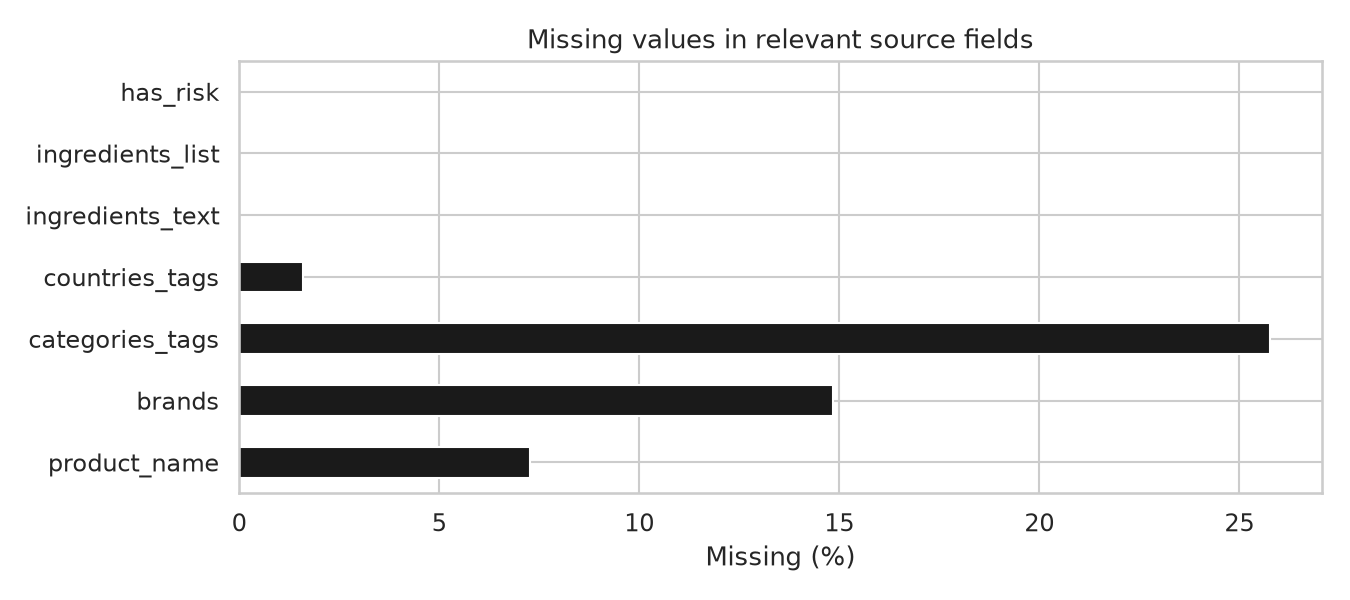

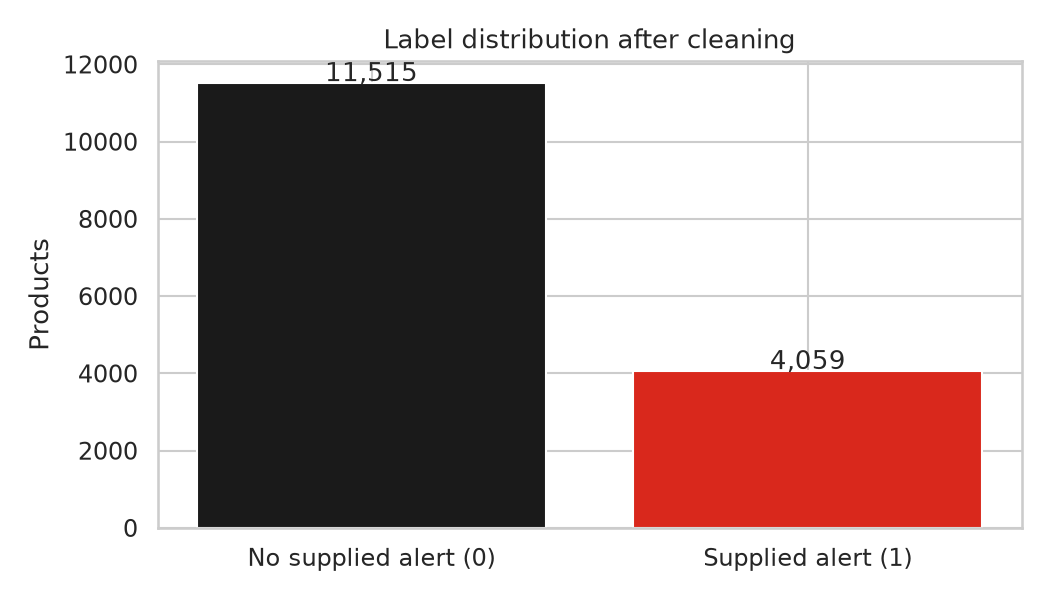

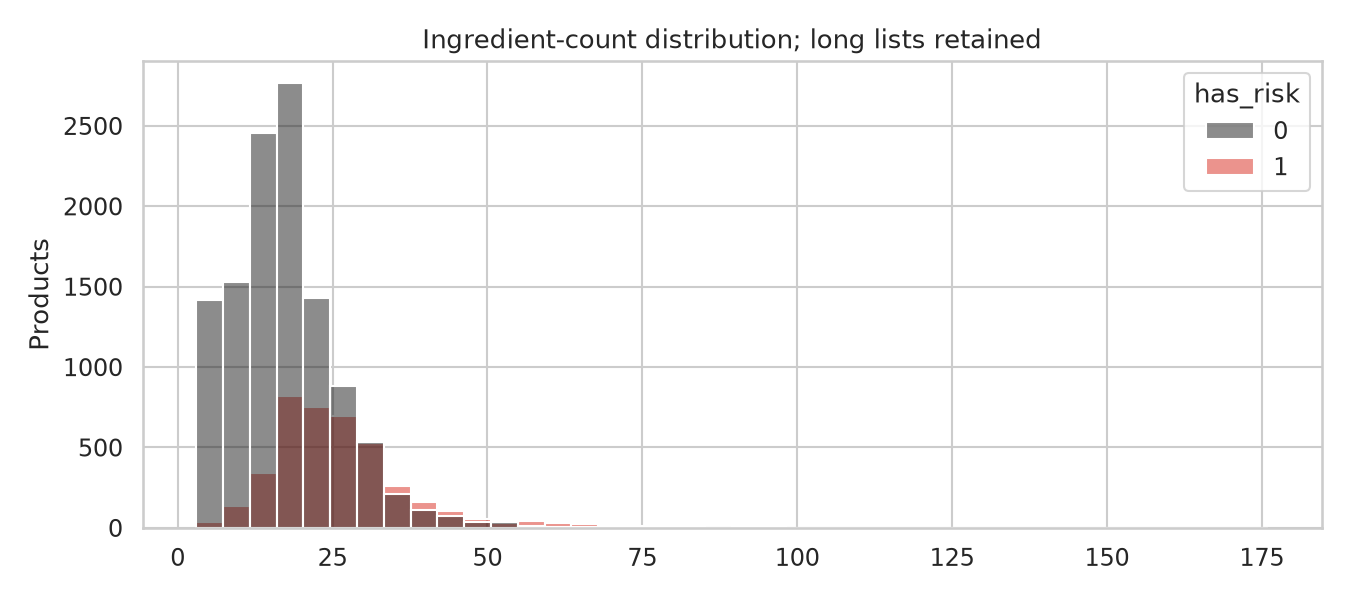

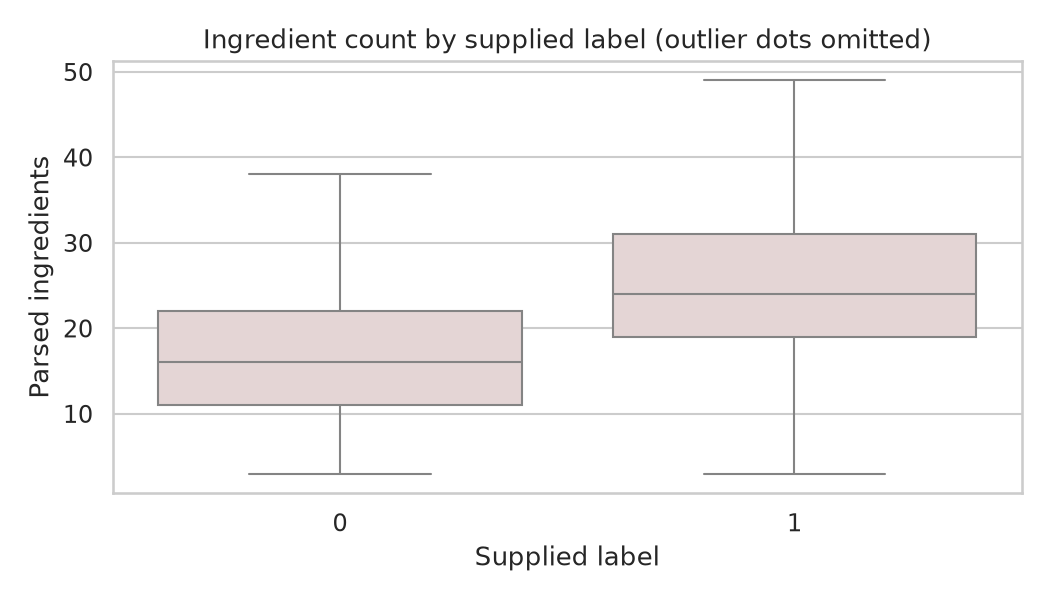

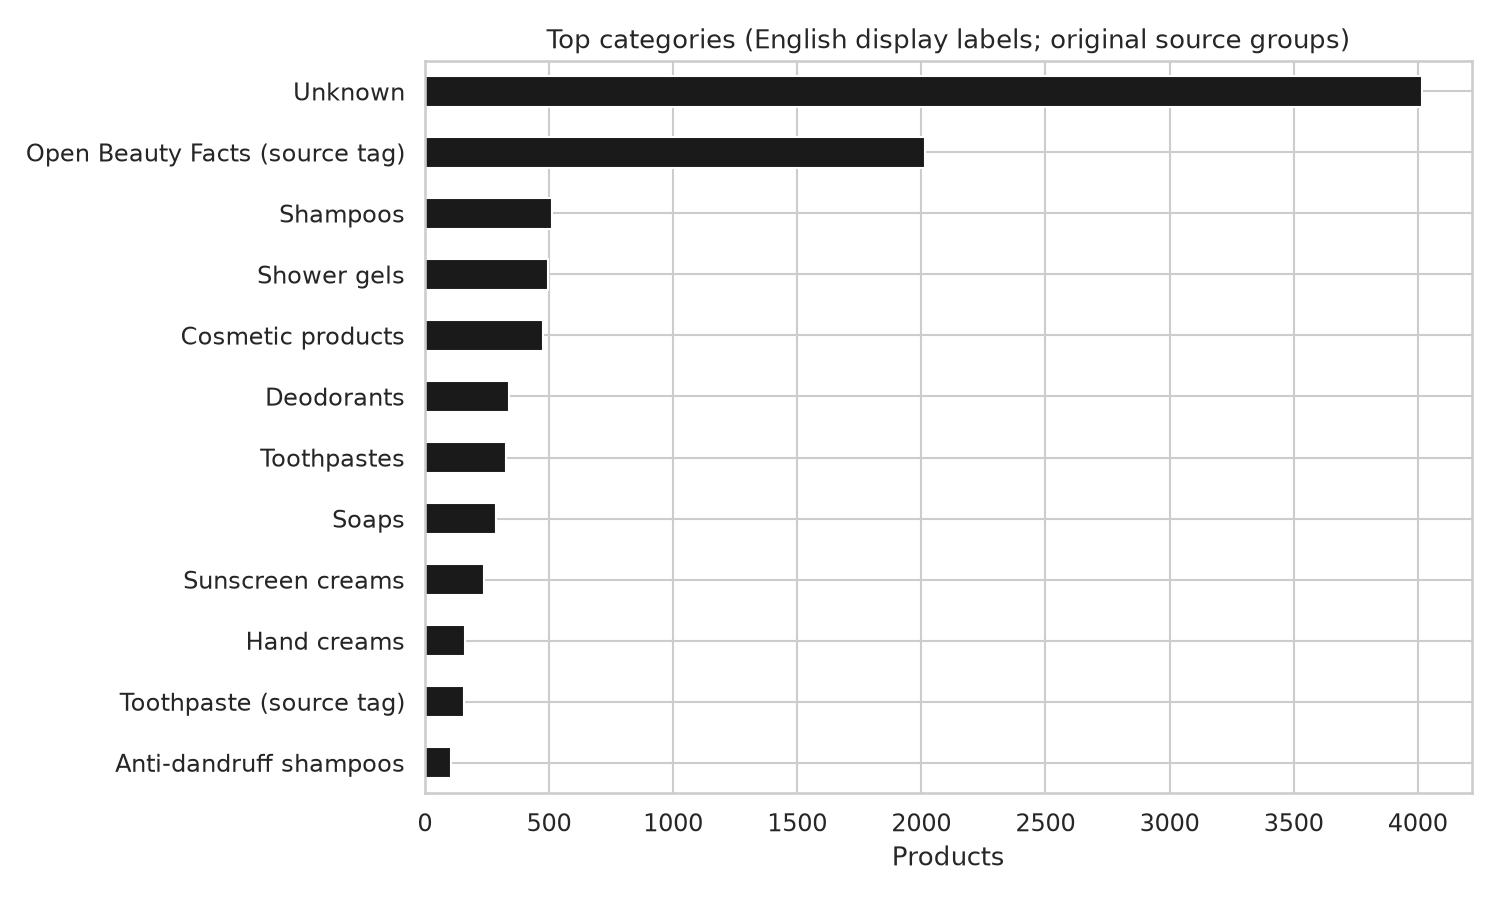

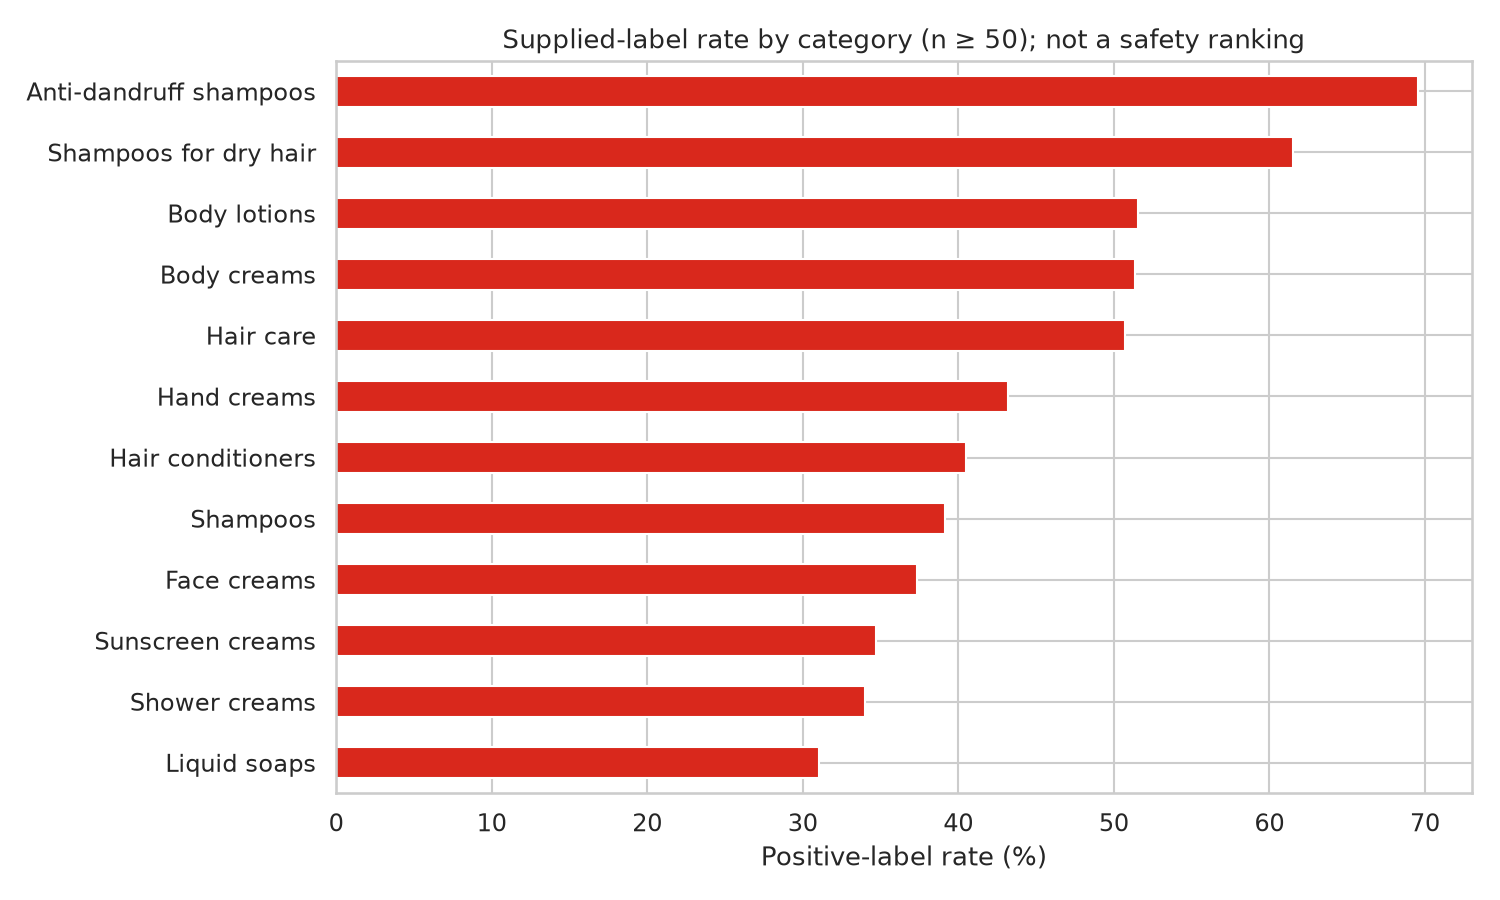

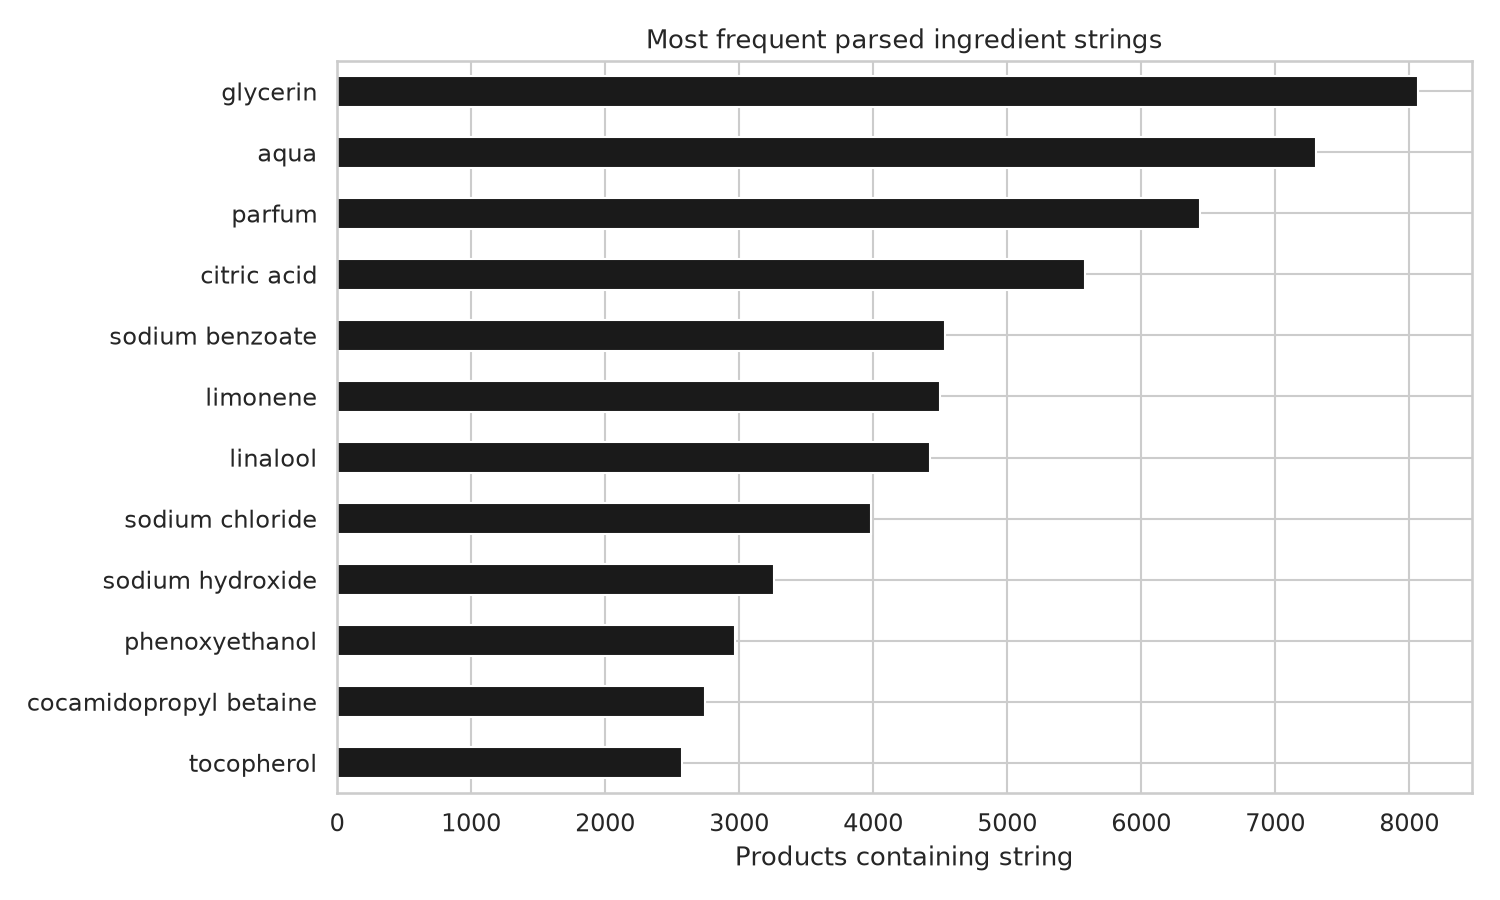

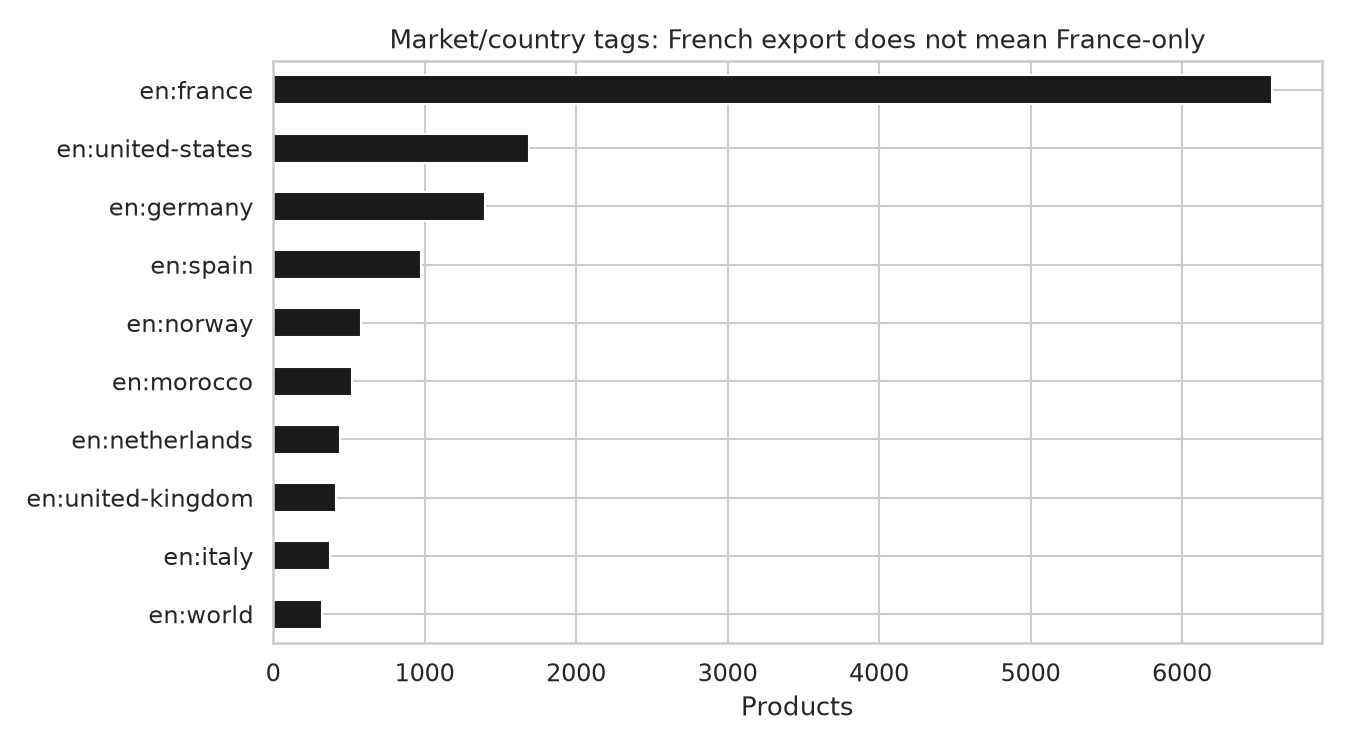

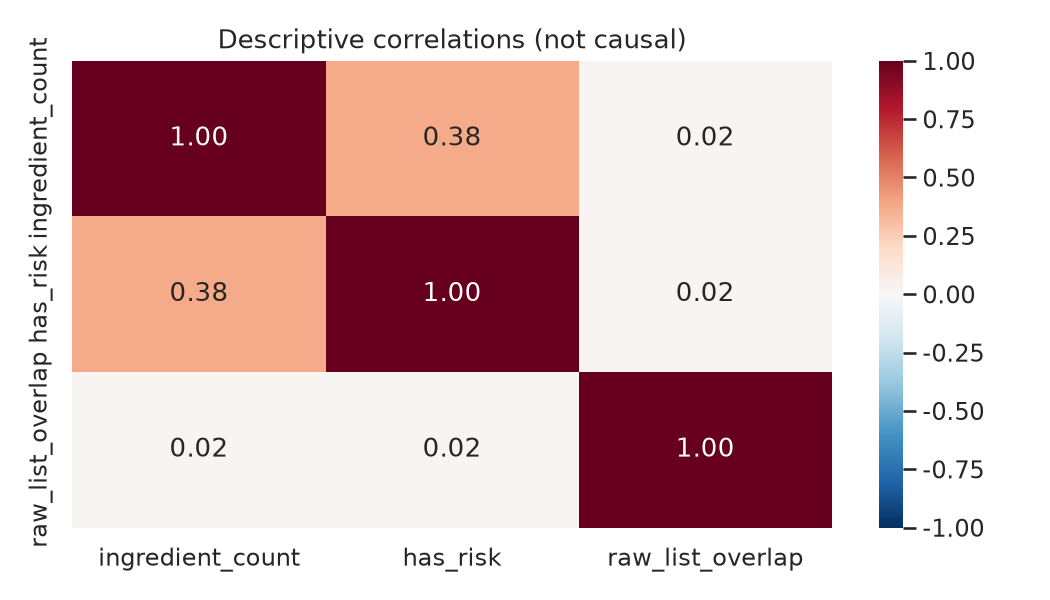

In [8]:
from src.analysis import english_category_label, save_eda

eda_summary, category_summary, ingredient_frequency = save_eda(clean, original, ROOT)
print('EDA summary')
display(pd.Series(eda_summary, name='value'))
display(category_summary.head(15).rename(index=english_category_label))
display(ingredient_frequency.head(20).to_frame('products'))

def show_figure(filename: str, width: int = 840) -> None:
    path = ROOT / 'reports' / 'figures' / filename
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print('Expected figure was not created:', filename)

for figure in [
    '01_missing_values.png', '02_target_distribution.png', '03_ingredient_count.png',
    '04_ingredients_by_label.png', '05_top_categories.png', '06_label_rate_by_category.png',
    '07_frequent_ingredients.png', '08_country_tags.png', '09_numeric_associations.png',
]:
    show_figure(figure)

In [9]:
class_balance = clean.groupby('has_risk').size().rename('products').to_frame()
class_balance['share'] = class_balance['products'] / len(clean)
display(class_balance)
display(clean[['ingredient_count', 'has_risk', 'raw_list_overlap']].corr(numeric_only=True))
print('Scope-status counts:', clean['scope_status'].value_counts(dropna=False).to_dict())

,products,share
has_risk,,
0,11515,0.739373
1,4059,0.260627


,ingredient_count,has_risk,raw_list_overlap
ingredient_count,1.000000,0.375907,0.016820
has_risk,0.375907,1.000000,0.017937
raw_list_overlap,0.016820,0.017937,1.000000


Scope-status counts: {'unclassified': 8746, 'recognized_cosmetic_or_personal_care': 6785, 'excluded_category': 43}


## 8. Feature engineering and preprocessing: ingredient lists only

The training input is `parsed_ingredients`: a list of normalized ingredient strings. If an on-disk clean CSV is reloaded, list literals are parsed by the same safe parser before modeling. No product name, barcode, brand, category, `has_risk`, risk category, reference-registry field, or future label-derived field is a predictor.

`IngredientPresenceEncoder` is fitted inside each training fold. It learns at most the 1,500 most frequent ingredients from that fold, emits binary presence columns, and appends `log1p(ingredient_count)`. Hence test-only ingredients cannot enter a fitted fold vocabulary; they are safely represented as absent top-vocabulary columns while their count remains usable. This is ingredient tokenization and binary representation — **not character TF-IDF** as a final model representation.

In [10]:
from src.features import IngredientPresenceEncoder
from src.experiments import model_candidates, run_experiments

print('IngredientPresenceEncoder.fit source:')
print(inspect.getsource(IngredientPresenceEncoder.fit))
print('IngredientPresenceEncoder.transform source:')
print(inspect.getsource(IngredientPresenceEncoder.transform))
print('Model-candidate source:')
print(inspect.getsource(model_candidates))
print('Experiment-runner source:')
print(inspect.getsource(run_experiments))

IngredientPresenceEncoder.fit source:
    def fit(self, X, y=None):
        if not isinstance(self.max_ingredients, int) or self.max_ingredients < 1:
            raise ValueError("max_ingredients must be a positive integer.")
        counts: Counter[str] = Counter()
        for ingredients in self._rows(X):
            counts.update(set(ingredients))
        ordered = sorted(counts.items(), key=lambda item: (-item[1], item[0]))
        self.vocabulary_ = {ingredient: index for index, (ingredient, _) in enumerate(ordered[: self.max_ingredients])}
        self.document_frequency_ = {ingredient: int(counts[ingredient]) for ingredient in self.vocabulary_}
        self.n_features_in_ = 1
        self.feature_names_out_ = np.asarray(
            [f"ingredient={ingredient}" for ingredient in self.vocabulary_] + ["log1p_ingredient_count"],
            dtype=object,
        )
        return self

IngredientPresenceEncoder.transform source:
    def transform(self, X):
        check_is_fitted(sel

In [11]:
def as_ingredient_list(value):
    """Use the same safe parser for CSV literals; retain genuine lists as lists."""
    if isinstance(value, list):
        return [canonical_text(item) for item in value if canonical_text(item)]
    return parse_ingredients(value)

model_input = clean['parsed_ingredients'].map(as_ingredient_list)
y = clean['has_risk'].astype(int)
groups = clean['formula_group'].astype(str)
assert model_input.map(type).eq(list).all()
assert model_input.map(len).gt(0).all()
assert not ({'has_risk', 'category', 'category_label', 'brands', 'code'} & {'parsed_ingredients'}), 'Only parsed ingredients are model input.'
display(pd.DataFrame({
    'parsed_ingredients': model_input.head(3),
    'ingredient_count': model_input.head(3).map(len),
    'supplied_label_for_audit_only': y.head(3),
    'formula_group': groups.head(3),
}))
print('Candidate names:', list(model_candidates().keys()))

,parsed_ingredients,ingredient_count,supplied_label_for_audit_only,formula_group
0,[caratteristiche prodotto: gel a base di acqua di arnica montana pot...,24,0,7dce3516667a01e0176341c82a0ecdce8bf73d9a867bce6abb008c44a286c03e
1,"[nutritional information magnesium stearate and silicon dioxide, ing...",13,0,1064c4c09a58bbaa2d190eb84d88eef74487c3a01bf75156b7277b11953b708b
2,"[aqua, glycerin, hydroxyethyl cellulose, phenoxyethanol, aloe barbad...",7,1,093398aa092cf7e3fea7982c662b7b0f2c63cf30dc0b2ee354baea037a1cd8e0


Candidate names: ['Majority baseline', 'Balanced Logistic Regression', 'Random Forest']


## 9. Grouped train/test design and leakage checks

A five-fold `StratifiedGroupKFold` provides a roughly 20% held-out test partition. Formula fingerprints cannot be shared between train and test. This preview uses exactly the grouping variable passed to the experiment runner; it never fits a vocabulary on the full dataset.

In [12]:
from sklearn.model_selection import StratifiedGroupKFold

outer_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(outer_splitter.split(model_input, y, groups))
train_groups, test_groups = groups.iloc[train_idx], groups.iloc[test_idx]
assert not set(train_groups) & set(test_groups), 'Formula-group leakage detected.'
split_summary = pd.DataFrame({
    'partition': ['train', 'test'],
    'rows': [len(train_idx), len(test_idx)],
    'positive_rate': [y.iloc[train_idx].mean(), y.iloc[test_idx].mean()],
    'formula_groups': [train_groups.nunique(), test_groups.nunique()],
})
display(split_summary)
print('Shared formula groups:', len(set(train_groups) & set(test_groups)))

,partition,rows,positive_rate,formula_groups
0,train,12459,0.260615,11866
1,test,3115,0.260674,2966


Shared formula groups: 0


In [13]:
train_vocab_observation = set(ingredient for items in model_input.iloc[train_idx] for ingredient in items)
test_vocab_observation = set(ingredient for items in model_input.iloc[test_idx] for ingredient in items)
unseen_test_ingredients = test_vocab_observation - train_vocab_observation
vocab_audit = pd.Series({
    'unique_observed_train_ingredients': len(train_vocab_observation),
    'unique_observed_test_ingredients': len(test_vocab_observation),
    'test_ingredients_unseen_in_train': len(unseen_test_ingredients),
    'examples_of_unseen_test_ingredients': sorted(unseen_test_ingredients)[:12],
    'encoder_rule': 'top 1500 ingredient presence features are learned from each training fold only',
})
display(vocab_audit)
print('Unseen test ingredients are expected. They must not be appended to a fitted fold vocabulary.')

unique_observed_train_ingredients                                                                        40420
unique_observed_test_ingredients                                                                         13070
test_ingredients_unseen_in_train                                                                          8454
examples_of_unseen_test_ingredients    [#10, #13, #14: synthetic fluorphlogopite, #15 coffee stearyl dimeth...
encoder_rule                           top 1500 ingredient presence features are learned from each training...
dtype: object

Unseen test ingredients are expected. They must not be appended to a fitted fold vocabulary.


## 10. Fresh training: benchmarks, AP tuning, grouped CV, and OOF F2 threshold selection

The following cell **actually trains** when this notebook is run. It creates the held-out split internally, evaluates the supplied model candidates with three-fold grouped training-only CV, fits/tunes the Random Forest as the selected ensemble focus, and writes dynamic reports/tables/figures.

The benchmark table includes a genuine majority baseline and actual Logistic Regression and Random Forest results; HistGradientBoosting may be included when the installed project configuration supports it. Random Forest tuning evaluates at least `min_samples_leaf ∈ {1, 2}` × `max_features ∈ {'sqrt', 0.2}` and selects by training-CV average precision. No old metrics are embedded in this notebook.

In [14]:
# Fresh training is intentional. Do not replace this call with a stale report reader.
training_started = time.perf_counter()
final_report, cv_table, test_predictions, feature_importances = run_experiments(clean, ROOT, folds=3)
training_seconds = time.perf_counter() - training_started
print(f'Fresh grouped experiment completed in {training_seconds / 60:.2f} minutes.')
print('Dynamic final report:')
print(json.dumps(final_report, indent=2, default=str))

[2026-10-31T04:56:10+00:00] Prepared deterministic grouped split: train=12459, test=3115, overlap=0.


[2026-10-31T04:56:10+00:00] Starting 3-fold training-only grouped CV for Majority baseline.


[2026-10-31T04:56:13+00:00] Completed training-only grouped CV for Majority baseline.


[2026-10-31T04:56:13+00:00] Starting 3-fold training-only grouped CV for Balanced Logistic Regression.


[2026-10-31T04:56:17+00:00] Completed training-only grouped CV for Balanced Logistic Regression.


...

[2026-10-31T04:57:14+00:00] Fitting Random Forest once on training partition for held-out comparison.


[2026-10-31T04:57:19+00:00] Starting 5-fold grouped overlapping-scope sensitivity analysis (6785 recognized rows).


[2026-10-31T04:57:27+00:00] Completed scope sensitivity analysis.


[2026-10-31T04:57:27+00:00] Saved final Random Forest model, metrics, tables, and figures.


Fresh grouped experiment completed in 1.31 minutes.
Dynamic final report:
{
  "primary_clean_rows": 15574,
  "train_rows": 12459,
  "test_rows": 3115,
  "train_positive_rate": 0.2606148165984429,
  "test_positive_rate": 0.2606741573033708,
  "formula_group_overlap_train_test": 0,
  "split_type": "First split from StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)",
  "selected_model": "Random Forest",
  "best_params": {
    "class_weight": "balanced_subsample",
    "max_features": 0.2,
    "min_samples_leaf": 2,
    "n_estimators": 200
  },
  "best_training_cv_average_precision": 0.9989700793385797,
  "best_training_cv_f1": 0.9986104672132448,
  "decision_threshold": 0.43866454707796715,
  "threshold_selection": "Training 3-fold grouped OOF Random Forest probabilities only; maximize F2 subject to recall >= 0.95.",
  "threshold_target_training_oof_recall": 0.95,
  "threshold_selection_details": {
    "training_oof_precision": 1.0,
    "training_oof_recall": 0.99753618724976

In [15]:
required_report_keys = {
    'selected_model', 'best_params', 'best_training_cv_average_precision', 'best_training_cv_f1',
    'decision_threshold', 'test_default_threshold', 'test_training_selected_threshold',
    'scope_sensitivity_rows', 'scope_sensitivity_5fold_grouped_cv', 'benchmark_cv_leader',
    'masking_applied', 'feature_scheme',
}
missing_report_keys = sorted(required_report_keys - set(final_report))
if missing_report_keys:
    raise KeyError(f'Experiment report is missing required fields: {missing_report_keys}')
if final_report['selected_model'] != 'Random Forest':
    raise ValueError(f"Expected ensemble focus 'Random Forest', received {final_report['selected_model']!r}")
if final_report['masking_applied'] is not False:
    raise ValueError('Unknown registry terms must not be masked from the supplied-label experiment.')
for operating_point in ('test_default_threshold', 'test_training_selected_threshold'):
    if 'f2' not in final_report[operating_point]:
        raise KeyError(f'{operating_point} must contain F2 in its exact score dictionary.')

report_summary = pd.Series({key: final_report[key] for key in required_report_keys}, name='value')
display(report_summary)
print('Random Forest is the selected ensemble focus. Benchmark CV leader:', final_report['benchmark_cv_leader'])
print('Feature scheme:', final_report['feature_scheme'])

test_default_threshold                {'accuracy': 0.9990369181380417, 'precision': 1.0, 'recall': 0.99630...
decision_threshold                                                                                   0.438665
feature_scheme                        Binary presence for up to 1,500 top ingredients by training document...
best_training_cv_f1                                                                                   0.99861
selected_model                                                                                  Random Forest
test_training_selected_threshold      {'accuracy': 0.9990369181380417, 'precision': 1.0, 'recall': 0.99630...
scope_sensitivity_5fold_grouped_cv    {'threshold': 0.5, 'metrics': {'accuracy': {'mean': 0.99793662490788...
masking_applied                                                                                         False
scope_sensitivity_rows                                                                                   6785
benchmark_

Random Forest is the selected ensemble focus. Benchmark CV leader: Balanced Logistic Regression
Feature scheme: Binary presence for up to 1,500 top ingredients by training document frequency plus log1p parsed ingredient-list length.


### 10.1 Training-only benchmark comparison

The comparison is reported exactly as calculated during fresh grouped CV. Selection and thresholding never use held-out rows. Average precision is the tuning objective for the Random Forest; F1, recall, precision, ROC-AUC, and F2 give complementary views rather than a single unsupported winner claim.

In [16]:
display(cv_table.round(4))
benchmark_columns = [column for column in cv_table.columns if column in {
    'model', 'accuracy_mean', 'precision_mean', 'recall_mean', 'f1_mean', 'f2_mean',
    'roc_auc_mean', 'average_precision_mean',
}]
if benchmark_columns:
    display(cv_table[benchmark_columns].round(4))

search_candidates = [
    ROOT / 'reports' / 'tables' / 'hyperparameter_search.csv',
    ROOT / 'reports' / 'tables' / 'random_forest_tuning.csv',
]
search_path = next((path for path in search_candidates if path.exists()), None)
if search_path is not None:
    search_results = pd.read_csv(search_path)
    tuning_columns = [column for column in search_results.columns if column.startswith('param_')] + [
        column for column in ('mean_test_average_precision', 'std_test_average_precision', 'rank_test_average_precision',
                               'mean_test_f1', 'mean_test_recall') if column in search_results.columns
    ]
    display(search_results[tuning_columns].sort_values(
        'rank_test_average_precision' if 'rank_test_average_precision' in search_results else tuning_columns[-1]
    ).head(12).round(4))
else:
    print('Tuning table not found; inspect the dynamic run_experiments output above.')
print('Chosen Random Forest parameters:', final_report['best_params'])

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,f2_mean,f2_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
0,Balanced Logistic Regression,0.9990,0.0007,1.0000,0.0000,0.9960,0.0027,0.9980,0.0013,0.9968,0.0021,0.9989,0.0012,0.9986,0.0014
1,Random Forest,0.9942,0.0007,0.9919,0.0019,0.9858,0.0012,0.9889,0.0013,0.9870,0.0011,0.9990,0.0005,0.9982,0.0008
2,Majority baseline,0.7394,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.2606,0.0001


,model,accuracy_mean,precision_mean,recall_mean,f1_mean,f2_mean,roc_auc_mean,average_precision_mean
0,Balanced Logistic Regression,0.9990,1.0000,0.9960,0.9980,0.9968,0.9989,0.9986
1,Random Forest,0.9942,0.9919,0.9858,0.9889,0.9870,0.9990,0.9982
2,Majority baseline,0.7394,0.0000,0.0000,0.0000,0.0000,0.5000,0.2606


,mean_test_average_precision,std_test_average_precision,rank_test_average_precision,mean_test_f1
0,0.9990,0.0009,1,0.9986
1,0.9988,0.0011,2,0.9986
2,0.9982,0.0008,3,0.9889
3,0.9971,0.0007,4,0.9767


Chosen Random Forest parameters: {'class_weight': 'balanced_subsample', 'max_features': 0.2, 'min_samples_leaf': 2, 'n_estimators': 200}


### 10.2 OOF threshold selection

The threshold is selected on training OOF scores only: among thresholds with recall ≥ 0.95, choose the one with the highest F2. It is an operating decision for supplied-label recall, not a calibrated probability threshold and not a healthcare rule.

OOF-selected decision threshold: 0.43866454707796715


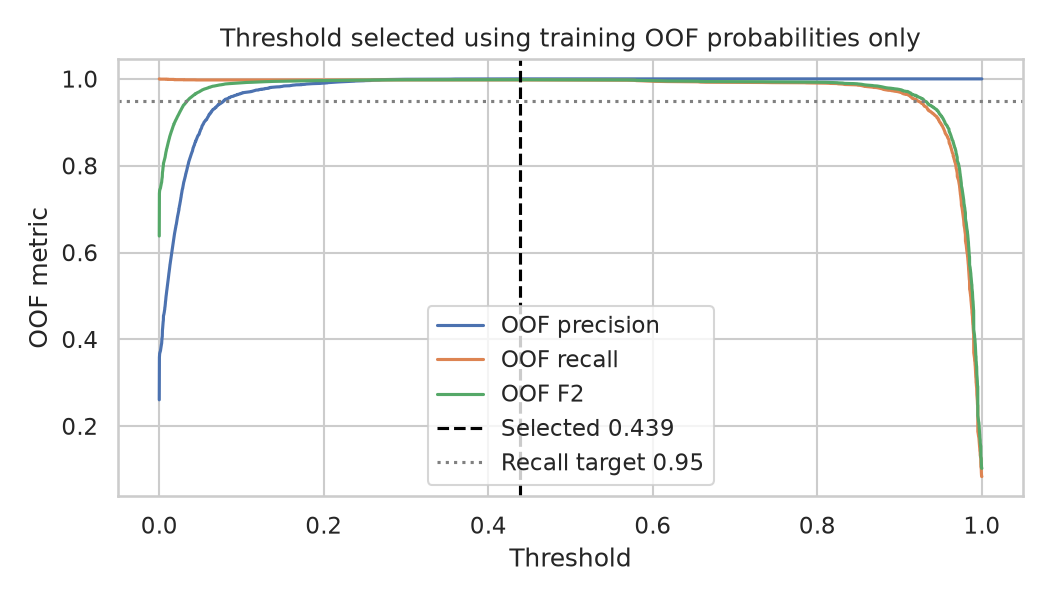

In [17]:
print('OOF-selected decision threshold:', final_report['decision_threshold'])
show_figure('13_threshold_selection.png')

## 11. Exact grouped held-out evaluation

Both the default 0.5 and training-selected threshold are evaluated on the same untouched grouped holdout. Ranking metrics (ROC-AUC and average precision) are based on scores; threshold metrics include F2. The final figures are regenerated from this run and have fixed, reviewable filenames.

,operating_point,accuracy,precision,recall,f1,f2,roc_auc,average_precision
0,Default threshold (0.5),0.999,1.0,0.9963,0.9981,0.997,0.999,0.9985
1,Training OOF-selected threshold,0.999,1.0,0.9963,0.9981,0.997,0.999,0.9985


test_default_threshold confusion matrix: [[2303, 0], [3, 809]]
test_training_selected_threshold confusion matrix: [[2303, 0], [3, 809]]
Held-out test metrics are stored in reports/final_metrics.json. Threshold selection used training grouped OOF probabilities only.
{
  "default_0.5": {
    "accuracy": 0.9990369181380417,
    "precision": 1.0,
    "recall": 0.9963054187192119,
    "f1": 0.9981492905613819,
    "f2": 0.9970421493714567,
    "roc_auc": 0.9989949391348616,
    "average_precision": 0.9985165465905167,
    "confusion_matrix": [
      [
        2303,
        0
      ],
      [
        3,
        809
      ]
    ]
  },
  "training_selected": {
    "accuracy": 0.9990369181380417,
    "precision": 1.0,
    "recall": 0.9963054187192119,
    "f1": 0.9981492905613819,
    "f2": 0.9970421493714567,
    "roc_auc": 0.9989949391348616,
    "average_precision": 0.9985165465905167,
    "confusion_matrix": [
      [
        2303,
        0
      ],
      [
        3,
        809
      ]
 

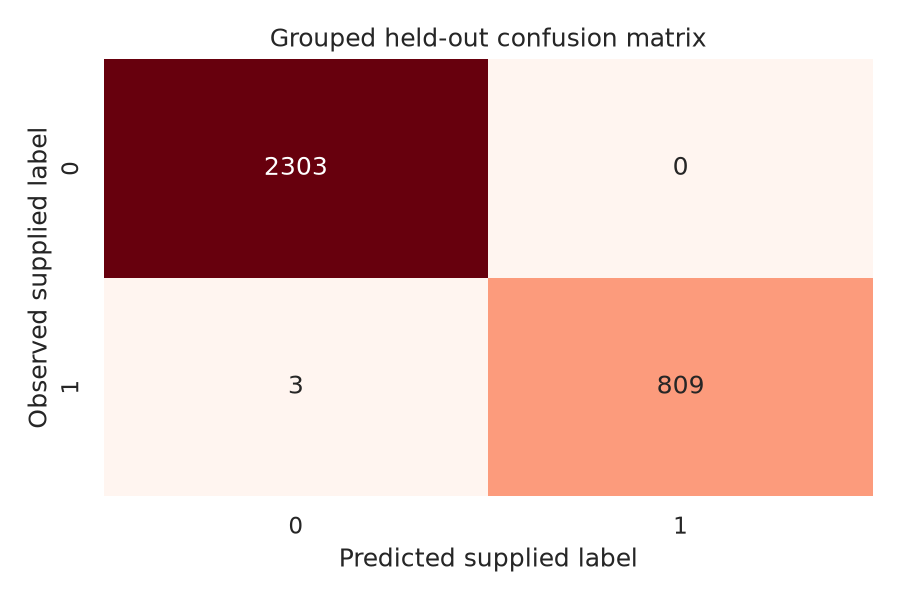

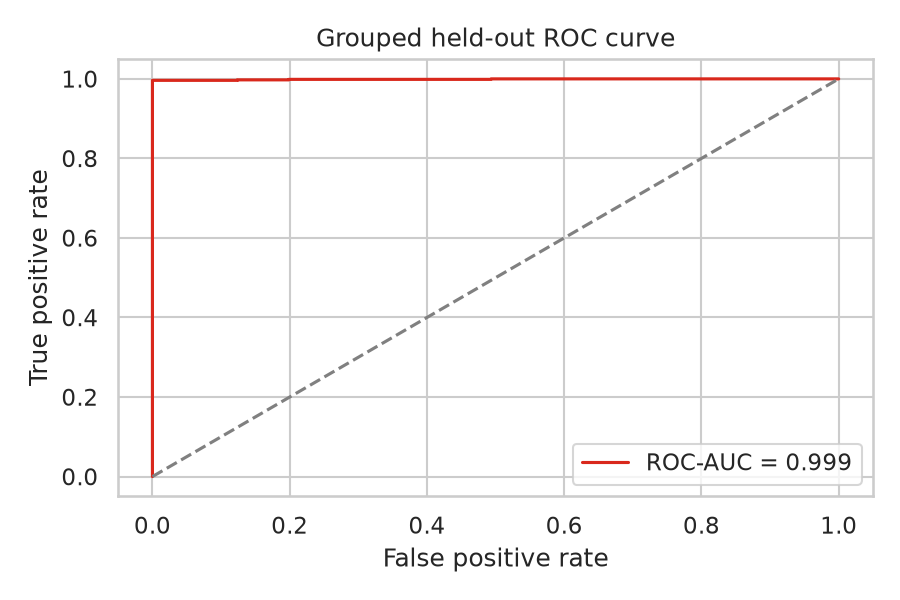

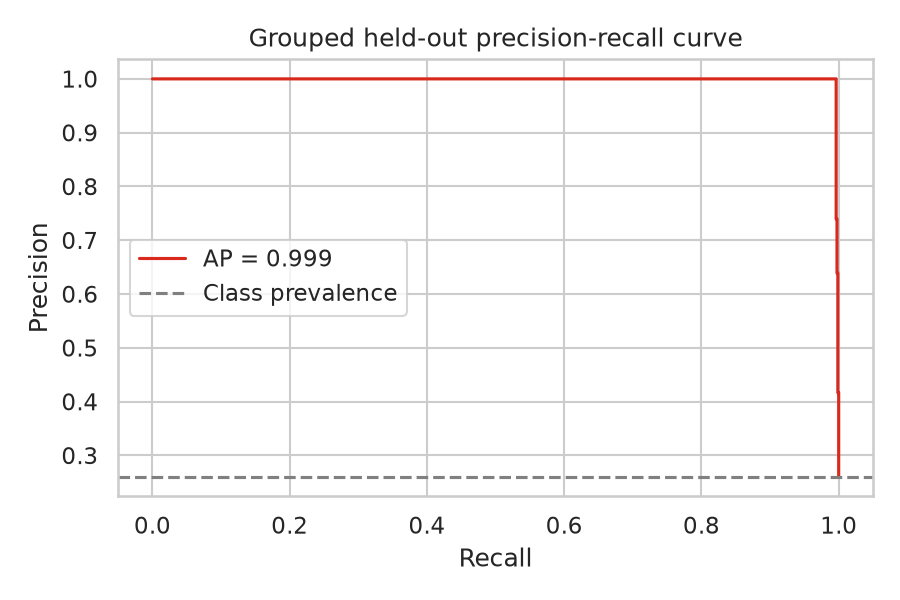

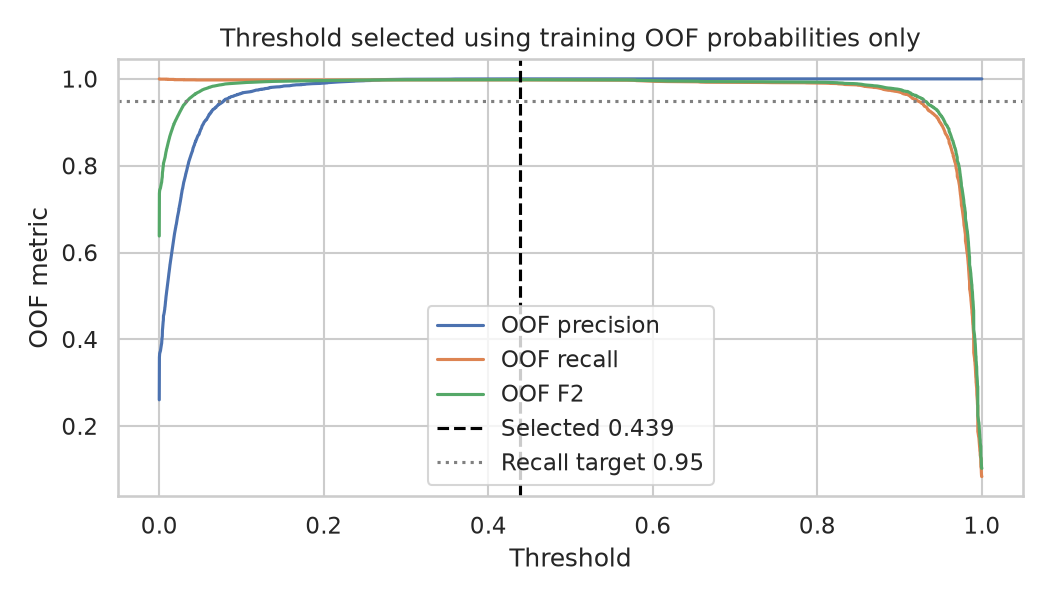

In [18]:
metric_rows = []
for operating_point, values in (
    ('Default threshold (0.5)', final_report['test_default_threshold']),
    ('Training OOF-selected threshold', final_report['test_training_selected_threshold']),
):
    metric_rows.append({'operating_point': operating_point, **{k: v for k, v in values.items() if k != 'confusion_matrix'}})
display(pd.DataFrame(metric_rows).round(4))
for operating_point in ('test_default_threshold', 'test_training_selected_threshold'):
    print(operating_point, 'confusion matrix:', final_report[operating_point]['confusion_matrix'])

classification_path = ROOT / 'reports' / 'classification_report.txt'
if classification_path.exists():
    print(classification_path.read_text(encoding='utf-8'))
for figure in ('10_confusion_matrix.png', '11_roc_curve.png', '12_precision_recall.png', '13_threshold_selection.png'):
    show_figure(figure)

## 12. Scope sensitivity

The recognized-cosmetic/personal-care subset is an overlapping-source sensitivity analysis, not external validation and not a regulatory classification. Unclassified observations remain in the primary supplied-label experiment; unknown registry substances are never removed or relabeled.

In [19]:
print('Scope sensitivity rows:', final_report['scope_sensitivity_rows'])
scope_cv = final_report['scope_sensitivity_5fold_grouped_cv']
if isinstance(scope_cv, dict):
    print('Sensitivity operating threshold:', scope_cv.get('threshold', 0.5))
    display(pd.DataFrame(scope_cv.get('metrics', scope_cv)).T.round(4))
else:
    display(scope_cv)

Scope sensitivity rows: 6785
Sensitivity operating threshold: 0.5


,mean,std
accuracy,0.9979,0.0023
precision,1.0000,0.0000
recall,0.9921,0.0090
f1,0.9960,0.0046
f2,0.9936,0.0072
roc_auc,0.9991,0.0007
average_precision,0.9986,0.0013


## 13. Error analysis and Random Forest interpretation

False positives and false negatives are errors relative to the supplied label, not proof about safety or regulatory status. Random Forest feature importances are non-negative mean-decrease-in-impurity (MDI) importances. MDI can favor high-cardinality/correlated features and is an association measure, not an ingredient toxicity score or causal effect.

Local explanations are implemented as **actual probability perturbations**: remove one present input feature/list item and recalculate the fitted model score. They describe context-dependent changes in this model’s supplied-label score. They are not coefficient signs, TF-IDF × weight calculations, SHAP values, or toxicological statements.

Held-out error-type counts:


,rows
error_type,
correct,3112
false_negative,3


,code,product_name,has_risk,predicted_label,score,error_type,parsed_ingredients
1325,626232111286,NaN,1,0,0.003152,false_negative,"[aqua / water / eau, glycerin, pca glyceryl oleate, coco-glucoside, ..."
2988,3050070004023,Après rasage parfumé,1,0,0.015347,false_negative,"[alcohol denat, aqua, parfum, peg-40 hydrogenated castor oil, linalo..."
4510,3350033307353,Crème dépilatoire peaux sensibles beurre de karité,1,0,0.024341,false_negative,"[aqua, ceteartyl alcohol, paraffinum liquidum, urea, calcium hydroxi..."


,term,importance
0,ingredient=phenoxyethanol,0.521940
1,ingredient=salicylic acid,0.110008
2,ingredient=methylisothiazolinone,0.090630
3,log1p_ingredient_count,0.056021
4,ingredient=methylchloroisothiazolinone,0.031581
5,ingredient=dimethicone,0.023109
6,ingredient=ethylhexylglycerin,0.014803
7,ingredient=carbomer,0.009361
8,ingredient=cetearyl alcohol,0.009150
9,ingredient=disodium edta,0.007760


Feature importance rows: 1501 | non-negative MDI: True


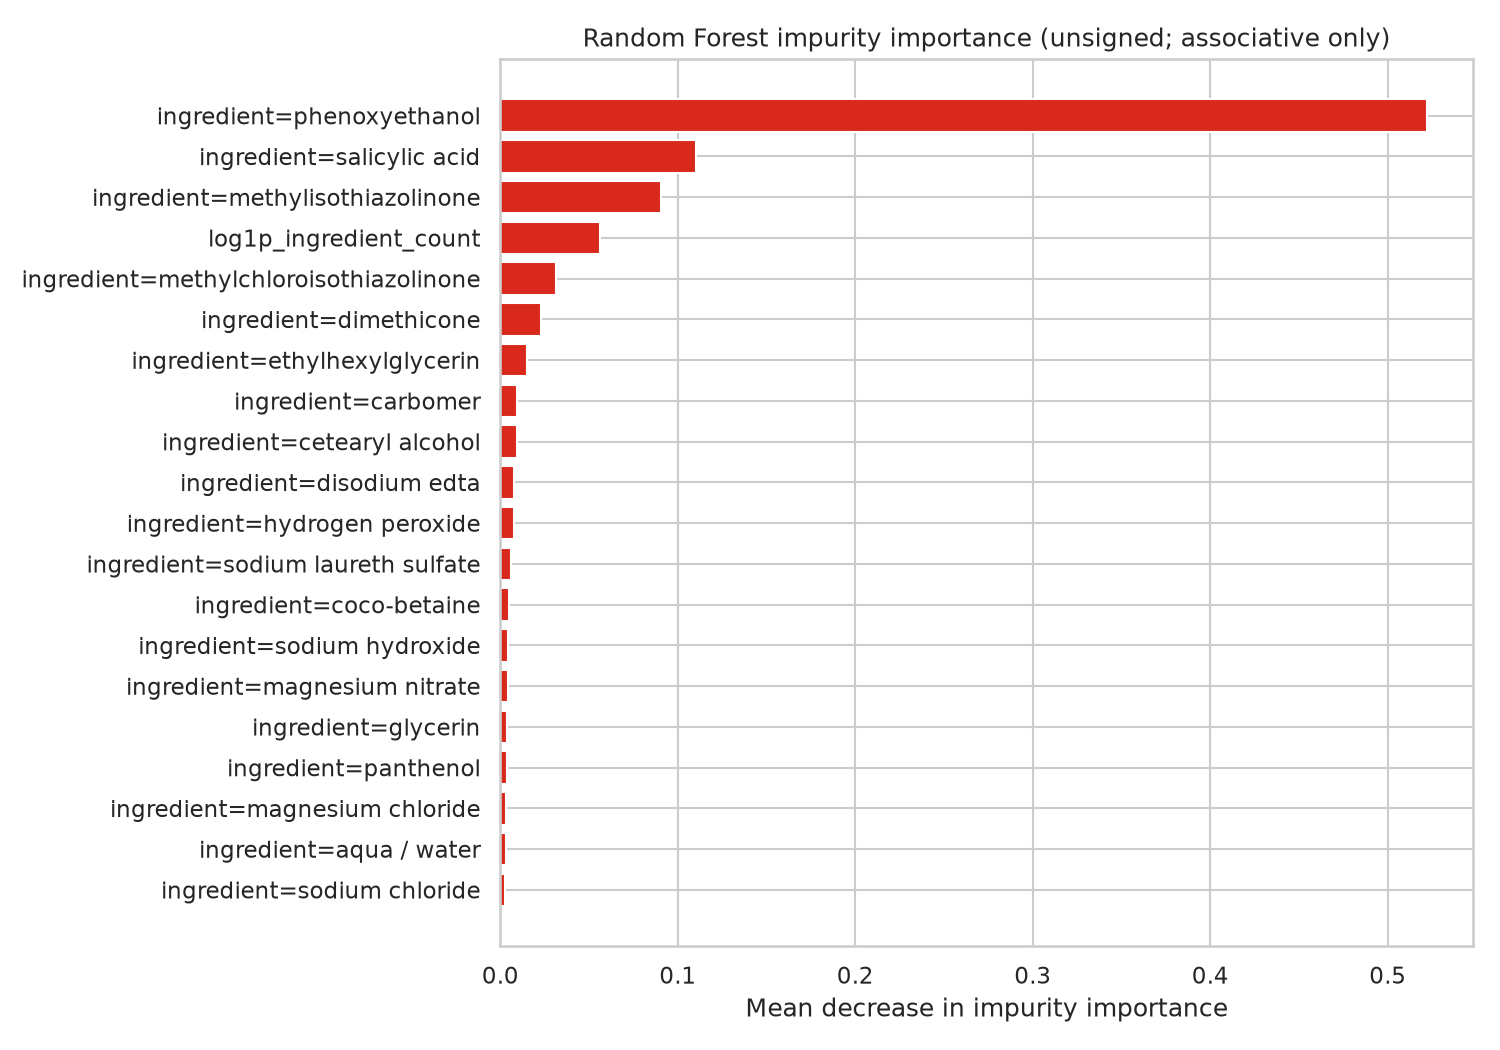

In [20]:
test_predictions = test_predictions.copy()
test_predictions['predicted_label'] = test_predictions['prediction_training_selected_threshold'].astype(int)
test_predictions['score'] = test_predictions['model_score']
test_predictions['error_type'] = np.select(
    [test_predictions['has_risk'].eq(0) & test_predictions['predicted_label'].eq(1),
     test_predictions['has_risk'].eq(1) & test_predictions['predicted_label'].eq(0)],
    ['false_positive', 'false_negative'], default='correct',
)
errors = test_predictions.loc[test_predictions['error_type'].ne('correct')].copy()
print('Held-out error-type counts:')
display(test_predictions['error_type'].value_counts(dropna=False).to_frame('rows'))
error_columns = [column for column in (
    'code', 'product_name', 'has_risk', 'predicted_label', 'score', 'error_type', 'parsed_ingredients'
) if column in errors.columns]
display(errors[error_columns].head(15))

importance_path = ROOT / 'reports' / 'tables' / 'feature_importance.csv'
if importance_path.exists():
    persisted_importances = pd.read_csv(importance_path)
else:
    persisted_importances = feature_importances.copy()
if not {'term', 'importance'}.issubset(persisted_importances.columns):
    raise KeyError('Feature importances must contain term and non-negative MDI importance columns.')
if (persisted_importances['importance'] < 0).any():
    raise ValueError('Random Forest MDI importances must be non-negative.')
display(persisted_importances.sort_values('importance', ascending=False).head(20))
print('Feature importance rows:', len(persisted_importances), '| non-negative MDI:', bool((persisted_importances['importance'] >= 0).all()))
show_figure('14_feature_importance.png')

In [21]:
from src.predict import explain_text, load_config, load_model, predict_text

model = load_model(ROOT / 'models' / 'cosmetic_risk_model.joblib')
config = load_config(ROOT / 'models' / 'model_config.json')
real_heldout = clean.iloc[test_idx[0]]
real_ingredients = as_ingredient_list(real_heldout['parsed_ingredients'])
real_text = ', '.join(real_ingredients)

print('Real held-out barcode:', real_heldout['code'])
print('Supplied label shown only for post-hoc audit:', int(real_heldout['has_risk']))
print('Predictor source signatures:')
print('predict_text:', inspect.signature(predict_text))
print('explain_text:', inspect.signature(explain_text))
local_prediction = predict_text(model, real_text, threshold=float(config['decision_threshold']))
local_explanation = explain_text(model, real_text)
display(local_prediction)
display(pd.DataFrame(local_explanation))

Real held-out barcode: 902980642
Supplied label shown only for post-hoc audit: 0
Predictor source signatures:
predict_text: (model, ingredients, category: 'str' = '', threshold: 'float' = 0.5) -> 'dict'
explain_text: (model, text, top_n: 'int' = 8) -> 'list[dict]'


{'has_risk': 0,
 'model_score': 0.0029513689450507367,
 'risk_probability': 0.003,
 'decision_threshold': 0.43866454707796715,
 'message': 'No supplied-label alert predicted; safety is not established.'}

,term,contribution,drop_one_probability_change,base_model_score,score_without_term,unsigned_impurity_importance,method
0,ingredient=aroma,0.000000,0.000000,0.002951,0.002951,0.001236,drop-one-present-feature (context-dependent; not SHAP)
1,ingredient=sodium benzoate,0.000000,0.000000,0.002951,0.002951,0.001170,drop-one-present-feature (context-dependent; not SHAP)
2,ingredient=aqua,0.000000,0.000000,0.002951,0.002951,0.001167,drop-one-present-feature (context-dependent; not SHAP)
3,ingredient=peg-40 hydrogenated castor oil,0.002951,0.002951,0.002951,0.000000,0.000326,drop-one-present-feature (context-dependent; not SHAP)
4,ingredient=sodium citrate,0.002951,0.002951,0.002951,0.000000,0.000267,drop-one-present-feature (context-dependent; not SHAP)
5,ingredient=sodium metabisulfite,0.000000,0.000000,0.002951,0.002951,0.000250,drop-one-present-feature (context-dependent; not SHAP)
6,ingredient=chlorhexidine digluconate,0.000000,0.000000,0.002951,0.002951,0.000079,drop-one-present-feature (context-dependent; not SHAP)
7,ingredient=xylitol,0.000000,0.000000,0.002951,0.002951,0.000043,drop-one-present-feature (context-dependent; not SHAP)


In [22]:
# Successful scoring of the actual held-out rows demonstrates that unseen ingredients are handled
# by the training-only encoder rather than added to a global vocabulary.
heldout_input = model_input.iloc[test_idx]
heldout_scores = model.predict_proba(heldout_input)[:, 1]
leakage_result = pd.Series({
    'heldout_rows_scored': len(heldout_scores),
    'test_ingredients_unseen_in_train': len(unseen_test_ingredients),
    'formula_groups_shared_between_train_and_test': len(set(train_groups) & set(test_groups)),
    'global_vocabulary_fit_used': False,
    'training_fold_vocabulary_rule': 'IngredientPresenceEncoder learns top 1500 ingredients during fit only',
})
display(leakage_result)
assert len(heldout_scores) == len(test_idx)
assert len(set(train_groups) & set(test_groups)) == 0

heldout_rows_scored                                                                                              3115
test_ingredients_unseen_in_train                                                                                 8454
formula_groups_shared_between_train_and_test                                                                        0
global_vocabulary_fit_used                                                                                      False
training_fold_vocabulary_rule                   IngredientPresenceEncoder learns top 1500 ingredients during fit only
dtype: object

## 14. SQL analysis

SQLite provides an auditable tabular view of the cleaned dataset. These descriptive queries do not participate in the predictive feature matrix or label construction.

In [23]:
sqlite_path = ROOT / 'data' / 'processed' / 'cosmetic_products.sqlite'
if not sqlite_path.exists():
    raise FileNotFoundError(f'Expected SQLite artifact missing: {sqlite_path}')
queries = {
    'Largest categories': """
        SELECT category_label, COUNT(*) AS products, AVG(has_risk) AS supplied_label_rate
        FROM products
        GROUP BY category_label
        HAVING COUNT(*) >= 25
        ORDER BY products DESC
        LIMIT 15
    """,
    'Scope counts': """
        SELECT scope_status, COUNT(*) AS products, AVG(has_risk) AS supplied_label_rate
        FROM products
        GROUP BY scope_status
        ORDER BY products DESC
    """,
    'Ingredient-count bands': """
        SELECT CASE
                 WHEN ingredient_count < 10 THEN 'under 10'
                 WHEN ingredient_count < 25 THEN '10–24'
                 WHEN ingredient_count < 50 THEN '25–49'
                 ELSE '50 or more'
               END AS ingredient_count_band,
               COUNT(*) AS products, AVG(has_risk) AS supplied_label_rate
        FROM products
        GROUP BY ingredient_count_band
        ORDER BY products DESC
    """,
}
with sqlite3.connect(sqlite_path) as connection:
    for label, query in queries.items():
        print(label)
        result = pd.read_sql_query(query, connection)
        if 'category_label' in result:
            result['category_label'] = result['category_label'].map(english_category_label)
        display(result)

Largest categories


,category_label,products,supplied_label_rate
0,Unknown,4016,0.248008
1,Open Beauty Facts (source tag),2013,0.276205
2,Shampoos,511,0.391389
3,Shower gels,496,0.223790
4,Cosmetic products,477,0.264151
5,Deodorants,340,0.044118
6,Toothpastes,326,0.018405
7,Soaps,287,0.080139
8,Sunscreen creams,239,0.347280
9,Hand creams,162,0.432099


Scope counts


,scope_status,products,supplied_label_rate
0,unclassified,8746,0.261377
1,recognized_cosmetic_or_personal_care,6785,0.260870
2,excluded_category,43,0.069767


Ingredient-count bands


,ingredient_count_band,products,supplied_label_rate
0,10–24,9510,0.209989
1,25–49,3623,0.494066
2,under 10,2173,0.040497
3,50 or more,268,0.686567


## 15. Tests, packaging, reproducibility, and handoff

The code is testable outside this notebook. Inspect tests rather than hiding the implementation; execute them from the project root after model artifacts are generated. The Dockerfile/package files describe a local packaging route and are not a claim that an online deployment or a Docker build was run here.

```bash
python -m pytest -q
python -m src.train --root .
streamlit run app.py
```

Joblib artifacts should only be loaded from trusted local files because deserialization can execute code. Preserve the raw source snapshot outside ordinary Git if its size or license requires it.

In [24]:
for path in sorted((ROOT / 'tests').glob('test_*.py')):
    print(f'\n### {path.relative_to(ROOT)}')
    print(path.read_text(encoding='utf-8'))

for relative in ('Dockerfile', 'requirements.txt', 'requirements-lock.txt', 'app.py'):
    path = ROOT / relative
    print(f'{relative}:', path.exists())

import subprocess
test_run = subprocess.run([sys.executable, '-m', 'pytest', '-q'], cwd=ROOT,
                          capture_output=True, text=True, check=False)
test_output = test_run.stdout + test_run.stderr
print(test_output)
(ROOT / 'reports' / 'test_results.txt').write_text(test_output, encoding='utf-8')
assert test_run.returncode == 0, 'Resolve automated-test failures before submission.'

expected_artifacts = [
    'models/cosmetic_risk_model.joblib', 'models/model_config.json', 'reports/final_metrics.json',
    'reports/tables/model_comparison_cv.csv', 'reports/tables/feature_importance.csv',
    'reports/tables/prediction_errors.csv', 'reports/figures/14_feature_importance.png',
]
display(pd.DataFrame({
    'artifact': expected_artifacts,
    'exists_after_fresh_run': [(ROOT / relative).exists() for relative in expected_artifacts],
}))


### tests/test_cleaning.py
import json
import pandas as pd
import pytest
from src.cleaning import parse_ingredients,formula_group,scope_status,clean_data
from src.deterministic import load_registry,match_ingredients
from src.predict import predict_text

def test_literal_parsing_and_normalization():
    assert parse_ingredients("['AQUA', ' GLYCERIN  ']")==['aqua','glycerin']

def test_not_eval():
    assert parse_ingredients("__import__('os').system('echo unsafe')")==[]

def test_not_prose_split():
    assert parse_ingredients('Aqua, Glycerin')==[]

def test_order_independent_formula_group():
    assert formula_group(['aqua','glycerin'])==formula_group(['glycerin','aqua','aqua'])

def test_empty_input_rejected():
    with pytest.raises(ValueError): predict_text(None,'')

def test_toothpaste_scope():
    assert scope_status('en:hygiene,en:toothpastes')=='recognized_cosmetic_or_personal_care'

def test_missing_registry_fails_explicitly(tmp_path):
    p=tmp_path/'registry.json';p.write_te

.......................                                                  [100%]
23 passed in 1.40s



,artifact,exists_after_fresh_run
0,models/cosmetic_risk_model.joblib,True
1,models/model_config.json,True
2,reports/final_metrics.json,True
3,reports/tables/model_comparison_cv.csv,True
4,reports/tables/feature_importance.csv,True
5,reports/tables/prediction_errors.csv,True
6,reports/figures/14_feature_importance.png,True


## 16. Conclusions and limitations

This notebook has produced a dynamic, formula-grouped evaluation of a Random Forest that learns binary ingredient presence and `log1p` ingredient count inside training folds. Its metrics describe reproduction of the **supplied** label on an internal held-out split. The exact results above are generated at execution time and should be reported with the dataset hash/version and configuration saved by the experiment runner.

Key limitations remain: the actual 16-substance registry and historical labeling logic are unavailable; ingredient strings can have OCR/noise/synonym issues; concentration and exposure are unknown; category tags are incomplete; related but not identical formulas may remain; source data are not an external validation cohort; and performance does not establish cosmetic safety, health outcomes, or regulatory compliance.

Next steps should begin with a dated, source-cited registry and independently reviewed labels, then add external/temporal validation, carefully governed synonym mappings, calibrated decision studies, and domain-expert review. Do not use this output for medical, regulatory, or consumer-safety decisions.